# RescueBot: Intelligent Autonomous Navigation and Survivor Detection Using POMDPs

**Course:** Reasoning and Decision Making Under Uncertainty (RDMU), Session III: Lab Activity, Exercise 2
**Deliverable 1 of 2:** analysis notebook (the Streamlit dashboard `app.py` is Deliverable 2)
**Shared model:** every calculation in this notebook comes from `rescuebot_core.py`, the same module the dashboard imports. There is only one implementation of the POMDP.

---

## Contents
1. Project introduction
2. Understanding POMDPs
3. Problem formulation
4. Environment construction
5. Transition model
6. Observation model
7. Reward model
8. Belief-state construction
9. Bayesian belief updates
10. RescueBot simulation
11. Monte Carlo planning (POMCP)
12. Alternative policy comparison
13. Results and performance analysis
14. Sensitivity analysis
15. Key findings and interpretation
16. Limitations and possible improvements
17. Final conclusion
18. References

## 1. Project introduction

### Assignment context
The lab slide (*Session III: Lab Activity – Exercise 2*, Dr. Sandip Kumar Roy) describes a robot, **RescueBot**, that must navigate a **foggy 4×4 grid** to reach a trapped survivor. Its visibility is limited: it can only sense nearby **heat signatures**, and the sensor is noisy. Movement can fail because of debris (80% success rate). The slide specifies the reward structure: **+100** for reaching the survivor, **−10 per move**, **−50 for entering a hazard zone**.

### Problem statement
RescueBot must decide, step by step, whether to **move** (Up/Down/Left/Right) or **scan**. It never observes the survivor's location, and because it has no odometry it is not even certain where *it* is after a few unreliable moves. The task is to act rationally anyway: maintain a probability distribution over what might be true, update it with Bayes' rule, and choose the actions with the highest expected **discounted** cumulative reward (the *discounted return*).

### Objectives (five substantive assignment requirements, together with performance evaluation)
The slide prints its task list with a duplicated item number, but it contains five substantive requirements, mapped one-to-one below.
| # | Requirement | Where it is implemented |
|---|---|---|
| 1 | Full stochastic transition model | `POMDPModel.move_matrix`, `transition_distribution`, `full_transition_matrix` (Section 5) |
| 2 | Belief-state representation | `Belief` – exact joint distribution b(r, q) (Sections 8–9) |
| 3 | Navigation simulation with belief updates and action selection | `RescueBotEnv`, `MissionRunner` (Section 10) |
| 4 | Policy optimisation by Monte Carlo planning | `POMCPPlanner` (Section 11), with value iteration used for the reference policies |
| 5 | Visualise belief evolution and robot path | Sections 8–13 |

### Expected outcomes
* A validated POMDP model whose probabilities provably sum to one.
* A working Bayes filter that turns noisy Cold/Warm/Hot readings into sharper beliefs.
* A POMCP planner that reasons over *hypothetical* worlds sampled from the belief and never reads the true survivor position.
* A statistically honest multi-episode comparison of POMCP against a random policy, a risk-aware belief heuristic, QMDP and an (idealised) clairvoyant reference.

In [1]:
import os, sys, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch
from matplotlib.colors import LinearSegmentedColormap
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display, Markdown

sys.path.insert(0, os.path.abspath("."))
import rescuebot_core as rb
from rescuebot_core import (RescueConfig, Belief, RescueBotEnv, MissionRunner, POMCPPlanner,
                            RiskAwareHeuristicPolicy, RandomPolicy, QMDPPolicy, ClairvoyantPolicy,
                            PolicySpec, evaluate_policies, summarise_evaluation, sensitivity_sweep,
                            value_iteration, wilson_interval, bootstrap_ci, entropy_bits,
                            sensor_with_noise, decision_consistency, ACTION_NAMES, OBS_NAMES,
                            UP, DOWN, LEFT, RIGHT, SCAN, OBS_NONE, OBS_COLD, OBS_WARM, OBS_HOT, fmt_cell)

pio.renderers.default = "notebook"           # interactive Plotly figures embedded in the notebook
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 140, "font.size": 10.5, "axes.titlesize": 12.5,
                     "axes.titleweight": "bold", "axes.labelsize": 11, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False})
pd.set_option("display.precision", 3)
os.makedirs("results", exist_ok=True)

# one palette shared with the dashboard (darker variants of the dashboard accents for white paper)
PAL = {"cyan": "#00A9CC", "blue": "#3478F6", "green": "#1FA463", "amber": "#E59A1C",
       "red": "#E04355", "grey": "#7C8DA6", "navy": "#0B1A33"}
POLICY_COLORS = {"POMCP": PAL["blue"], "Risk-aware heuristic": PAL["cyan"], "QMDP": PAL["amber"],
                 "Random": PAL["grey"], "Clairvoyant (reference)": PAL["green"]}
PROB_CMAP = LinearSegmentedColormap.from_list("prob", ["#F4F8FC", "#9FD8EA", "#3478F6", "#0B1A33"])
N_JOBS = min(2, os.cpu_count() or 1)
print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)
print("Parallel workers for evaluation:", N_JOBS)

numpy 2.5.3 | pandas 3.0.5 | matplotlib 3.11.2
Parallel workers for evaluation: 2


## 2. Understanding POMDPs

**Markov Decision Process (MDP).** An MDP $(S, A, T, R, \gamma)$ assumes the agent *knows the current state*. If RescueBot knew both its own cell and the survivor's cell, it could simply follow a shortest safe path. In this notebook that idealised case is solved exactly by **value iteration** and used as the *clairvoyant reference*.

**Partially Observable MDP (POMDP).** A POMDP $(S, A, T, O, Z, R, \gamma)$ (Kaelbling, Littman & Cassandra, 1998) adds an observation space $O$ and an observation model $Z(o \mid s', a)$. The agent no longer sees $s$; it receives noisy observations that are only *statistically related* to $s$.

| Concept | RescueBot example |
|---|---|
| **Hidden state** | The survivor's cell is never observed directly. After failed moves the robot's own cell is hidden too, because a failed move ("debris") produces no signal. |
| **Noisy observation** | A *Hot* reading is likely, but not certain, when the survivor is within 1 cell; a *Cold* reading can still occur close by (5%). |
| **Transition probability** | "Move Right" reaches the next cell with probability 0.8 and leaves the robot in place with probability 0.2. |
| **Observation probability** | $Z(\text{Hot} \mid d \le 1) = 0.75$ versus $Z(\text{Hot} \mid d \ge 4) = 0.05$. |
| **Belief state** | $b(r, q)$: the probability that the robot is in cell $r$ *and* the survivor is in cell $q$. The belief is a **sufficient statistic** for the whole action–observation history. |
| **Reward function** | +100 for reaching the survivor, −10 per attempted move, −50 extra for entering a hazard. |
| **Policy optimisation** | A policy maps beliefs to actions. Exact POMDP solutions are intractable in general, so we plan online with **Monte Carlo tree search over beliefs (POMCP)**. |

**Why RescueBot needs a POMDP.** Treating the most likely survivor cell as true (an MDP approximation) ignores the *value of information*: a Scan costs no reward points but can change which way the robot should go. Only a model that reasons about future observations can trade "act now" against "look first". Section 12 shows the failure mode of an approximation that ignores this, QMDP.

## 3. Problem formulation

$$\text{POMDP} = (S, A, T, O, Z, R, \gamma)$$

**States.** $s = (r, q)$ with robot cell $r \in \{0..15\}$ and survivor cell $q \in \mathcal{Q}$, where $\mathcal{Q}$ is the set of 14 non-hazard cells. That gives $16 \times 14 = 224$ joint states. States with $r = q$ are **terminal** (survivor reached) and absorbing. The hazard map $\{(2,2), (3,3)\}$ (one-based) is a **known, static** parameter rather than part of the state.

**Actions.** $A = \{\text{Up}, \text{Down}, \text{Left}, \text{Right}, \text{Scan}\}$.

**Transitions.** For a movement action $a$ with intended cell $n(r,a)$:
$$T\big((r',q') \mid (r,q), a\big) = \mathbb{1}[q'=q]\,\Big(p\,\mathbb{1}[r'=n(r,a)] + (1-p)\,\mathbb{1}[r'=r]\Big),\quad p = 0.8$$
If $n(r,a)$ lies off the grid then $n(r,a)=r$, and both terms add up to a certain stay. Scan: $T = \mathbb{1}[r'=r,\,q'=q]$. There is no sideways slip.

**Observations.** $O = \{\text{None}, \text{Cold}, \text{Warm}, \text{Hot}\}$. Movement always yields None (likelihood 1); Scan yields a heat reading.

**Observation model:** an imperfect, distance-banded Cold/Warm/Hot sensor. The bands are Manhattan distances $d(r', q')$ of 0–1, 2–3 and ≥ 4 (modelling assumptions, configurable):

| Manhattan distance | P(Cold) | P(Warm) | P(Hot) |
|---|---:|---:|---:|
| 0–1 | 0.05 | 0.20 | 0.75 |
| 2–3 | 0.20 | 0.65 | 0.15 |
| ≥ 4 | 0.75 | 0.20 | 0.05 |

**Rewards** (from the slide; scan cost 0 by default because the slide specifies none):
$$R(s,a,s') = \underbrace{-10\cdot\mathbb{1}[a \ne \text{Scan}]}_{\text{every attempted move}} \;\underbrace{-\,50\cdot\mathbb{1}[r' \in H,\ r' \ne r]}_{\text{entering a hazard}} \;+\; \underbrace{100\cdot\mathbb{1}[r' = q]}_{\text{rescue}} \;-\; c_{scan}\mathbb{1}[a=\text{Scan}]$$

**Discount** $\gamma = 0.95$: a reward $t$ steps ahead is worth $0.95^t$ of its face value (a rescue 10 steps away is worth $0.95^{10}\cdot 100 \approx 60$). Discounting encodes "minimise time" (earlier rewards are worth more). In the general infinite-horizon theory it also keeps returns finite. The RescueBot mission itself is finite, limited to 30 decisions, so discounting here mainly expresses the time preference.

**Reward terminology used throughout.** *Immediate reward* $r_t$ is the reward of a single step. *Cumulative reward* $\sum_t r_t$ is the undiscounted episode total. *Discounted return* $\sum_t \gamma^t r_t$ is what POMCP maximises in expectation. Cumulative reward and discounted return are reported separately in all evaluations.

### Modelling assumptions
1. **Coordinates.** Internally zero-based (row, col) with row 0 at the top and "Up" decreasing the row. Every displayed position is **one-based**: `display = (row+1, col+1)`, so the grid runs from (1,1) to (4,4).
2. **Default scenario** (demonstration values, since the slide prescribes no positions): start (1,1), survivor (4,4), hazards (2,2) and (3,3). All are configurable.
3. **Hazards are traversable but penalised.** The penalty applies on *entering* a hazard. Remaining in a hazard after a failed move is not charged again.
4. **Rescue detection.** The robot recognises the survivor on contact, which ends the episode. A mission that continues therefore tells the robot that it is *not* co-located with the survivor, and the belief update uses this information.
5. **No localisation sensor.** Only Scan produces a reading. Movement outcomes are unobserved, so position uncertainty can grow.
6. **Episode limit** of 30 real decisions. At decision $t$ the planner is told $H_{rem} = 30 - t$. Its tree depth is $\min(10, H_{rem})$ and its rollouts stop at the deadline (Section 11).

In [2]:
cfg = RescueConfig()                  # default demonstration scenario
model = cfg.public_model()            # what the AGENT is allowed to know (no survivor location)
print("Configuration:")
for k, v in cfg.to_dict().items():
    print(f"  {k:18s} = {v}")
print("\nAgent-visible model has a 'survivor' attribute:", hasattr(model, "survivor"))
print("Joint states (incl. terminal):", len(model.state_space()), "| non-terminal:", len(model.state_space(False)))

Configuration:
  rows               = 4
  cols               = 4
  start              = (0, 0)
  survivor           = (3, 3)
  hazards            = ((1, 1), (2, 2))
  p_success          = 0.8
  sensor_band_edges  = (1, 3)
  sensor_table       = ((0.05, 0.2, 0.75), (0.2, 0.65, 0.15), (0.75, 0.2, 0.05))
  rescue_reward      = 100.0
  move_cost          = 10.0
  hazard_penalty     = 50.0
  scan_cost          = 0.0
  gamma              = 0.95
  max_steps          = 30

Agent-visible model has a 'survivor' attribute: False
Joint states (incl. terminal): 224 | non-terminal: 210


## 4. Environment construction

The grid below shows every element of the default scenario. **The survivor's position is drawn here for the reader only.** It is stored solely inside the simulator `RescueBotEnv`, and the planner's model object (`cfg.public_model()`) does not contain it.

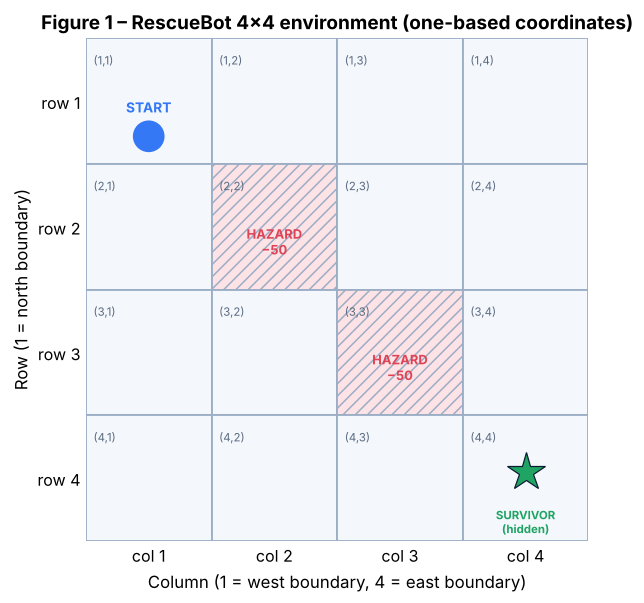

Safe cells   : (1,1), (1,2), (1,3), (1,4), (2,1), (2,3), (2,4), (3,1), (3,2), (3,4), (4,1), (4,2), (4,3), (4,4)
Hazard cells : (2,2), (3,3)
Boundaries   : a move that would leave rows 1–4 / columns 1–4 keeps the robot in place.


In [3]:
def draw_grid(ax, cfg, title=None, show_survivor=True, path=None, est_path=None, annotate_coords=True):
    R, C = cfg.rows, cfg.cols
    for r in range(R):
        for c in range(C):
            haz = (r, c) in cfg.hazards
            ax.add_patch(Rectangle((c, r), 1, 1, facecolor="#FDE3E6" if haz else "#F4F8FC",
                                   edgecolor="#9BAEC5", lw=1.2, hatch="///" if haz else None))
            if annotate_coords:
                ax.text(c + 0.06, r + 0.12, f"({r+1},{c+1})", fontsize=7.5, color="#5B6B82", va="top")
            if haz:
                ax.text(c + 0.5, r + 0.62, "HAZARD\n−50", ha="center", va="center", fontsize=8.5,
                        color=PAL["red"], fontweight="bold")
    s = cfg.start
    ax.text(s[1] + 0.5, s[0] + 0.55, "START", ha="center", va="center",
            fontsize=9, color=PAL["blue"], fontweight="bold")
    ax.add_patch(plt.Circle((s[1] + 0.5, s[0] + 0.78), 0.12, color=PAL["blue"]))
    if show_survivor:
        q = cfg.survivor
        ax.plot(q[1] + 0.5, q[0] + 0.45, marker="*", ms=26, color=PAL["green"], mec=PAL["navy"], mew=0.8)
        ax.text(q[1] + 0.5, q[0] + 0.85, "SURVIVOR\n(hidden)", ha="center", va="center", fontsize=7.5,
                color=PAL["green"], fontweight="bold")
    if path is not None:
        xs = [p[1] + 0.5 for p in path]; ys = [p[0] + 0.5 for p in path]
        ax.plot(xs, ys, "-o", color=PAL["blue"], lw=2.4, ms=5, alpha=0.85, label="Actual path (ground truth)")
    if est_path is not None:
        xs = [p[1] + 0.5 + 0.12 for p in est_path]; ys = [p[0] + 0.5 + 0.12 for p in est_path]
        ax.plot(xs, ys, "--s", color=PAL["amber"], lw=1.8, ms=4, alpha=0.9, label="Most likely position (belief)")
    ax.set_xlim(0, C); ax.set_ylim(R, 0); ax.set_aspect("equal")
    ax.set_xticks(np.arange(C) + 0.5, [f"col {c+1}" for c in range(C)])
    ax.set_yticks(np.arange(R) + 0.5, [f"row {r+1}" for r in range(R)])
    ax.tick_params(length=0); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
    if title: ax.set_title(title)

fig, ax = plt.subplots(figsize=(5.6, 5.6))
draw_grid(ax, cfg, "Figure 1 – RescueBot 4×4 environment (one-based coordinates)")
ax.set_xlabel("Column (1 = west boundary, 4 = east boundary)"); ax.set_ylabel("Row (1 = north boundary)")
plt.tight_layout(); plt.show()
safe = [fmt_cell(model.cell(i)) for i in model.safe_cells]
print("Safe cells   :", ", ".join(safe))
print("Hazard cells :", ", ".join(fmt_cell(h) for h in cfg.hazards))
print("Boundaries   : a move that would leave rows 1–4 / columns 1–4 keeps the robot in place.")

*Interpretation.* Hazards sit on the main diagonal, so the shortest path from (1,1) to (4,4) has to detour around them: the safe 6-move routes run along the edges (for example Down×3 then Right×3). The survivor marker is for the reader; the planner cannot see it.

## 5. Transition model

**Requirement 1.** The robot-only movement matrix $M_a[r, r']$ is built first and lifted to the joint state with the survivor held fixed:
$T\big((r',q)\mid(r,q),a\big)=M_a[r,r']$. Duplicate outcomes are **aggregated**. At a boundary the "successful" outcome *and* the debris failure both leave the robot in place, so their probabilities 0.8 + 0.2 add up to 1.

**Worked examples** (one-based):
* At (2,1), *Right*: P(→(2,2)) = 0.8, P(stay at (2,1)) = 0.2. (2,2) is a hazard, so success costs −10 −50.
* At (1,1), *Up*: off-grid, so P(stay at (1,1)) = 0.8 + 0.2 = **1.0**.
* *Scan*: P(stay) = 1.

In [4]:
def show_dist(cell, a):
    s = (model.idx(cell), model.idx(cfg.survivor))
    d = model.transition_distribution(s, a)
    return ", ".join(f"P(robot→{fmt_cell(model.cell(r2))}) = {p:.2f}" for (r2, q2), p in sorted(d.items()))

for cell, a in [((1, 0), RIGHT), ((0, 0), UP), ((0, 0), LEFT), ((2, 3), DOWN), ((1, 2), SCAN)]:
    print(f"{fmt_cell(cell)} + {ACTION_NAMES[a]:5s} -> {show_dist(cell, a)}")

# ----- automated validation of the complete transition model -----
checks = []
for a in rb.ACTIONS:
    states, T = model.full_transition_matrix(a)
    checks.append({"action": ACTION_NAMES[a], "matrix shape": T.shape,
                   "min prob": T.min(), "max |row sum − 1|": np.abs(T.sum(1) - 1).max(),
                   "survivor ever moves": any(s2[1] != s[1] for s in states for s2 in model.transition_distribution(s, a)),
                   "terminal absorbing": all(model.transition_distribution((q, q), a) == {(q, q): 1.0} for q in model.safe_cells)})
val = pd.DataFrame(checks)
display(val)
assert (val["max |row sum − 1|"] < 1e-12).all() and (val["min prob"] >= 0).all()
assert not val["survivor ever moves"].any() and val["terminal absorbing"].all()
print("✔ All 5 transition matrices (224×224) are valid stochastic matrices; survivor static; terminals absorbing.")

(2,1) + Right -> P(robot→(2,1)) = 0.20, P(robot→(2,2)) = 0.80
(1,1) + Up    -> P(robot→(1,1)) = 1.00
(1,1) + Left  -> P(robot→(1,1)) = 1.00
(3,4) + Down  -> P(robot→(3,4)) = 0.20, P(robot→(4,4)) = 0.80
(2,3) + Scan  -> P(robot→(2,3)) = 1.00


,action,matrix shape,min prob,max |row sum − 1|,survivor ever moves,terminal absorbing
0,Up,"(224, 224)",0.0,0.0,False,True
1,Down,"(224, 224)",0.0,0.0,False,True
2,Left,"(224, 224)",0.0,0.0,False,True
3,Right,"(224, 224)",0.0,0.0,False,True
4,Scan,"(224, 224)",0.0,0.0,False,True


✔ All 5 transition matrices (224×224) are valid stochastic matrices; survivor static; terminals absorbing.


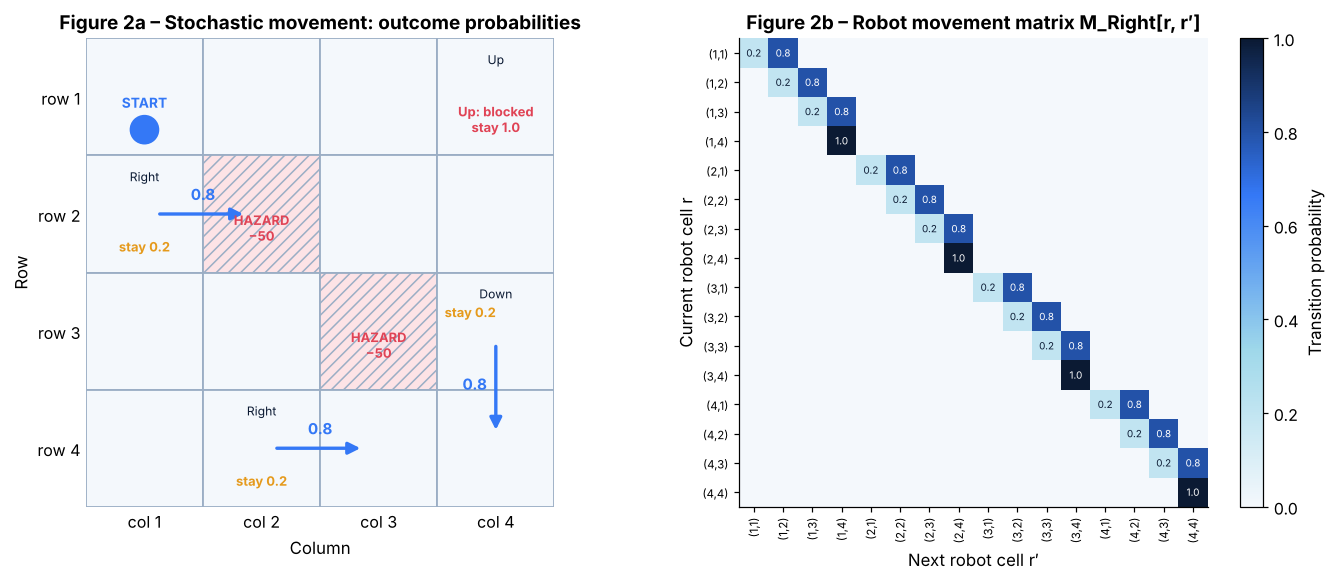

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.4), gridspec_kw={"width_ratios": [1, 1.25]})
# (a) arrows from representative cells
ax = axes[0]
draw_grid(ax, cfg, "Figure 2a – Stochastic movement: outcome probabilities", show_survivor=False, annotate_coords=False)
examples = [((1, 0), RIGHT), ((0, 3), UP), ((3, 1), RIGHT), ((2, 3), DOWN)]
for cell, a in examples:
    i = model.idx(cell); j = model.next_cell[a][i]
    cx, cy = cell[1] + 0.5, cell[0] + 0.5
    if j != i:
        t = model.cell(j)
        ax.add_patch(FancyArrowPatch((cx, cy), (t[1] + 0.5, t[0] + 0.5), arrowstyle="-|>", mutation_scale=16,
                                     color=PAL["blue"], lw=2.2, shrinkA=10, shrinkB=12))
        vertical = t[1] == cell[1]
        lx, ly = ((cx + t[1] + 0.5) / 2 - 0.18, (cy + t[0] + 0.5) / 2) if vertical else ((cx + t[1] + 0.5) / 2, (cy + t[0] + 0.5) / 2 - 0.12)
        ax.text(lx, ly, "0.8", color=PAL["blue"], fontsize=10, ha="center", fontweight="bold")
        ax.text(cx, cy + 0.32 if not vertical else cy - 0.12, "stay 0.2", color=PAL["amber"], fontsize=8.5,
                ha="center" if not vertical else "right", fontweight="bold")
    else:
        ax.text(cx, cy + 0.3, f"{ACTION_NAMES[a]}: blocked\nstay 1.0", color=PAL["red"], fontsize=8.5, ha="center",
                fontweight="bold")
    ax.text(cx, cy - 0.28, ACTION_NAMES[a], fontsize=8, ha="center", color=PAL["navy"])
ax.set_xlabel("Column"); ax.set_ylabel("Row")
# (b) M_Right heatmap
ax = axes[1]
M = model.move_matrix[RIGHT]
im = ax.imshow(M, cmap=PROB_CMAP, vmin=0, vmax=1)
labels = [fmt_cell(model.cell(i)) for i in range(model.n)]
ax.set_xticks(range(16), labels, rotation=90, fontsize=7.5); ax.set_yticks(range(16), labels, fontsize=7.5)
ax.set_xlabel("Next robot cell r′"); ax.set_ylabel("Current robot cell r")
ax.set_title("Figure 2b – Robot movement matrix M_Right[r, r′]"); ax.grid(False)
cb = plt.colorbar(im, ax=ax, fraction=0.046); cb.set_label("Transition probability")
for i in range(16):
    for j in range(16):
        if M[i, j] > 0:
            ax.text(j, i, f"{M[i,j]:.1f}", ha="center", va="center", fontsize=6.5,
                    color="white" if M[i, j] > 0.5 else PAL["navy"])
plt.tight_layout(); plt.show()

*Interpretation.* Each row of $M_{Right}$ has exactly one 0.8 entry (the cell to the east) and one 0.2 on the diagonal (a debris failure), except for the four column-4 cells. There a move east is blocked, the two outcomes coincide, and the diagonal entry is 1.0. Lifting $M_a$ to the joint 224-state space never changes the survivor component.

## 6. Observation model

$Z(o \mid s', a)$ for $a=$ Scan depends only on the Manhattan distance $d(r', q')$. After a movement action the only possible observation is None, with likelihood 1, so movement leaves the survivor belief untouched apart from the "not yet rescued" information.

**Why this sensor creates uncertainty.** The likelihood rows overlap. A *Warm* reading is the most likely reading at distance 2–3, but it also occurs 20% of the time very close to or far from the survivor. One reading therefore never identifies the survivor's cell. It only reweights entire **distance rings** around the robot's believed position, and it can only distinguish between cells at different distances from the robot. This is why the robot must scan from *different* positions to triangulate.

In [6]:
d = np.arange(0, 7)
tab = np.array([model.sensor_table[model.band(x)] for x in d])
fig = go.Figure()
for k, (name, col) in enumerate([("Cold", "#3478F6"), ("Warm", "#E59A1C"), ("Hot", "#E04355")]):
    fig.add_bar(x=[f"d = {x}" for x in d], y=tab[:, k], name=name, marker_color=col,
                text=[f"{v:.0%}" for v in tab[:, k]], textposition="outside")
for x0, x1, label in [(-0.5, 1.5, "band 1: d ≤ 1"), (1.5, 3.5, "band 2: 2 ≤ d ≤ 3"), (3.5, 6.5, "band 3: d ≥ 4")]:
    fig.add_vrect(x0=x0, x1=x1, fillcolor="#3478F6", opacity=0.04, line_width=0,
                  annotation_text=label, annotation_position="top left", annotation_font_size=11)
fig.update_layout(title="Figure 3 – Heat-sensor likelihood Z(o | d) by robot–survivor Manhattan distance",
                  xaxis_title="Manhattan distance between robot and survivor (cells)",
                  yaxis_title="Probability of reading", yaxis=dict(range=[0, 1.05], tickformat=".0%"),
                  barmode="group", template="plotly_white", height=430, legend_title="Reading",
                  margin=dict(t=70, l=60, r=20, b=60))
fig.show()
print("Row sums:", tab.sum(1))
assert np.allclose(sum(model.obs_lik[o] for o in rb.HEAT_OBS), 1.0)
print("✔ Observation likelihoods sum to 1 for every (robot, survivor) pair.")

Row sums: [1. 1. 1. 1. 1. 1. 1.]
✔ Observation likelihoods sum to 1 for every (robot, survivor) pair.


*Interpretation.* *Hot* is strong evidence of proximity (likelihood ratio 0.75 / 0.05 = 15 between the nearest and farthest bands), and *Cold* is equally strong evidence of distance. *Warm* is the least decisive reading: it favours the middle band about 3:1.

## 7. Reward model

The reward is returned with its components (`move_cost`, `hazard`, `rescue`, `scan_cost`), so every point in a cumulative-reward plot can be traced to its source. A move costs −10 **even when it fails** or is blocked by a boundary. Hazard entry adds −50. Reaching the survivor gives +100 once and ends the episode; terminal states are absorbing with zero reward.

,Event,From,Action,To,move_cost,hazard,rescue,scan_cost,"R(s,a,s′)"
0,Successful move into a safe cell,"(1,1)",Right,"(1,2)",-10.0,0.0,0.0,0.0,-10.0
1,Failed move (debris),"(1,1)",Right,"(1,1)",-10.0,0.0,0.0,0.0,-10.0
2,Blocked by boundary,"(1,1)",Up,"(1,1)",-10.0,0.0,0.0,0.0,-10.0
3,"Move into hazard (2,2)","(2,1)",Right,"(2,2)",-10.0,-50.0,0.0,0.0,-60.0
4,Move that reaches the survivor,"(4,3)",Right,"(4,4)",-10.0,0.0,100.0,0.0,90.0
5,Scan (baseline: free),"(2,3)",Scan,"(2,3)",0.0,0.0,0.0,-0.0,0.0


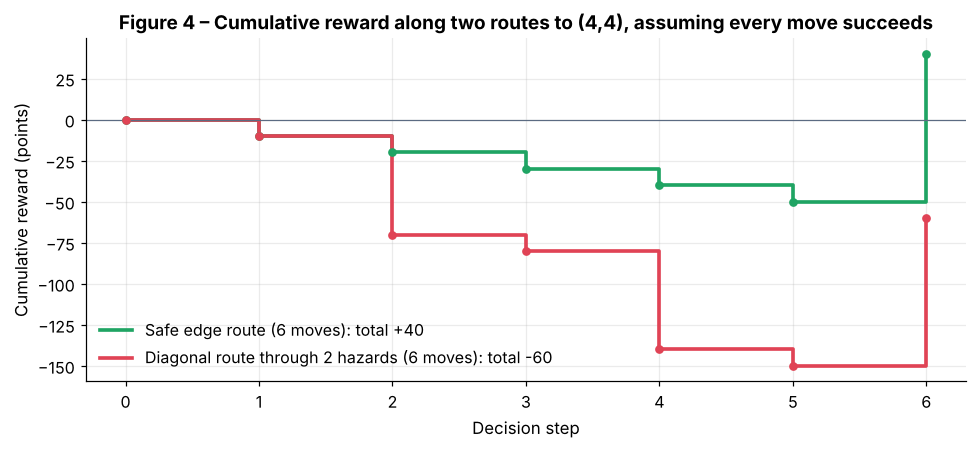

In [7]:
cases = [("Successful move into a safe cell", (0, 0), RIGHT, (0, 1)),
         ("Failed move (debris)", (0, 0), RIGHT, (0, 0)),
         ("Blocked by boundary", (0, 0), UP, (0, 0)),
         ("Move into hazard (2,2)", (1, 0), RIGHT, (1, 1)),
         ("Move that reaches the survivor", (3, 2), RIGHT, (3, 3)),
         ("Scan (baseline: free)", (1, 2), SCAN, (1, 2))]
rows = []
for name, r, a, r2 in cases:
    rew, comp = model.reward(model.idx(r), a, model.idx(r2), model.idx(cfg.survivor))
    rows.append({"Event": name, "From": fmt_cell(r), "Action": ACTION_NAMES[a], "To": fmt_cell(r2), **comp, "R(s,a,s′)": rew})
display(pd.DataFrame(rows))

# cumulative-reward illustration on the optimal clairvoyant route vs a route through a hazard
routes = {"Safe edge route (6 moves)": [DOWN, DOWN, DOWN, RIGHT, RIGHT, RIGHT],
          "Diagonal route through 2 hazards (6 moves)": [RIGHT, DOWN, RIGHT, DOWN, RIGHT, DOWN]}
fig, ax = plt.subplots(figsize=(9, 4.2))
for (name, acts), col in zip(routes.items(), [PAL["green"], PAL["red"]]):
    r, cum, ys = model.start_idx, 0.0, [0.0]
    for a in acts:
        r2 = model.next_cell[a][r]
        rew, _ = model.reward(r, a, r2, model.idx(cfg.survivor)); cum += rew; ys.append(cum); r = r2
    ax.step(range(len(ys)), ys, where="post", lw=2.4, color=col, label=f"{name}: total {cum:+.0f}")
    ax.scatter(range(len(ys)), ys, color=col, s=22, zorder=3)
ax.axhline(0, color="#5B6B82", lw=0.8)
ax.set_title("Figure 4 – Cumulative reward along two routes to (4,4), assuming every move succeeds")
ax.set_xlabel("Decision step"); ax.set_ylabel("Cumulative reward (points)"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

*Interpretation.* Even with perfect movement, the safe 6-move route earns only +40 (−60 in move costs, +100 for the rescue). Crossing the two hazards turns the same mission into −60. Under γ = 0.95 the discounted value of the safe route is smaller still. Section 13 returns to this: the slide's rewards leave little margin for search effort.

## 8. Belief-state construction

The initial belief puts the robot at the known start with probability 1 and spreads the survivor uniformly over the 13 safe cells other than the start:
$$b_0(r, q) = \mathbb{1}[r = r_0]\cdot\frac{\mathbb{1}[q \in \mathcal{Q}\setminus\{r_0\}]}{13}$$
The two quantities we visualise are the **marginals**:
$$P(\text{robot}=r) = \sum_q b(r,q), \qquad P(\text{survivor}=q) = \sum_r b(r,q).$$
They are *not* independent. After the robot's position becomes uncertain, a Hot reading means "the survivor is near wherever I actually am", which couples the two.

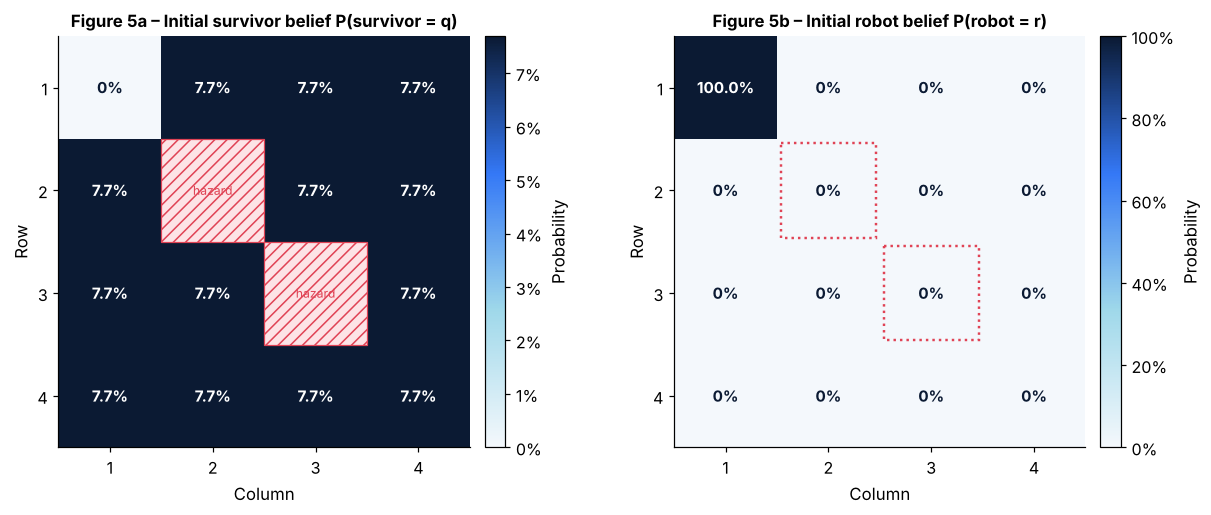

Σ b0 = 1.000000000000; survivor entropy = 3.700 bits (log2 13 = 3.700); robot entropy = -0.000 bits


In [8]:
def prob_heatmap(ax, grid, title, cfg=cfg, vmax=None, truth=None, truth_label="true", cbar=True, fontsize=10, robot=False):
    # robot=True: the robot CAN be inside a hazard cell, so its probability is shown there (red outline)
    vmax = vmax or max(grid.max(), 1e-9)
    im = ax.imshow(grid, cmap=PROB_CMAP, vmin=0, vmax=vmax)
    for r in range(cfg.rows):
        for c in range(cfg.cols):
            if robot and (r, c) in cfg.hazards:
                ax.add_patch(Rectangle((c - .46, r - .46), .92, .92, fill=False, ec=PAL["red"], lw=1.6, ls=":"))
            if (r, c) in cfg.hazards and not robot:
                ax.add_patch(Rectangle((c - .5, r - .5), 1, 1, facecolor="#FDE3E6", edgecolor=PAL["red"], hatch="///", lw=0.8))
                ax.text(c, r, "hazard", ha="center", va="center", fontsize=fontsize - 2, color=PAL["red"])
            else:
                v = grid[r, c]
                ax.text(c, r, f"{v:.1%}" if v >= 0.0005 else "0%", ha="center", va="center", fontsize=fontsize,
                        color="white" if v > 0.55 * vmax else PAL["navy"], fontweight="bold")
    if truth is not None:
        ax.add_patch(Rectangle((truth[1] - .48, truth[0] - .48), .96, .96, fill=False, ec=PAL["green"], lw=2.6, ls="--"))
    ax.set_xticks(range(cfg.cols), [str(c + 1) for c in range(cfg.cols)])
    ax.set_yticks(range(cfg.rows), [str(r + 1) for r in range(cfg.rows)])
    ax.set_xlabel("Column"); ax.set_ylabel("Row"); ax.set_title(title, fontsize=11); ax.grid(False)
    if cbar:
        cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.set_label("Probability"); cb.formatter = matplotlib.ticker.PercentFormatter(1.0, decimals=0); cb.update_ticks()
    return im

b0 = Belief.initial(model)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
prob_heatmap(axes[0], b0.survivor_marginal(), "Figure 5a – Initial survivor belief P(survivor = q)")
prob_heatmap(axes[1], b0.robot_marginal(), "Figure 5b – Initial robot belief P(robot = r)", robot=True)
plt.tight_layout(); plt.show()
print(f"Σ b0 = {b0.joint.sum():.12f}; survivor entropy = {b0.survivor_entropy():.3f} bits (log2 13 = {np.log2(13):.3f}); robot entropy = {b0.robot_entropy():.3f} bits")

*Interpretation.* With no evidence yet, all 13 candidate cells are equally likely (≈ 7.7% each, maximum entropy log₂13 ≈ 3.70 bits). Hazard cells and the start cell hold exactly 0%. The robot belief is a point mass because the start position is known.

## 9. Bayesian belief updates

**Derivation** (the discrete Bayes filter; Thrun, Burgard & Fox, 2005, ch. 2; applied to grid-based robot localisation by Fox, Burgard & Thrun, 1999). Bayes' rule over the hidden next state, given the prior belief and action $a$, then observation $o$:
$$b'(s') = P(s'\mid b,a,o) = \frac{P(o\mid s',a)\,P(s'\mid b,a)}{P(o\mid b,a)} = \eta\; Z(o\mid s',a)\sum_{s} T(s'\mid s,a)\,b(s), \qquad \eta^{-1} = \sum_{s'} Z(o\mid s',a)\sum_s T(s'\mid s,a)b(s).$$

`Belief.update` implements this in three explicit stages:
1. **Predict:** $\bar b(r',q) = \sum_r M_a[r,r']\,b(r,q)$, a matrix product $M_a^\top b$ (the survivor column is unchanged).
2. **Correct:** multiply by $Z(o\mid r',q)$ and by the continuation indicator $\mathbb{1}[r'\ne q]$ ("not rescued yet").
3. **Normalise** by $\eta$. If the evidence is zero, an `ImpossibleObservationError` is raised. The belief is *never* silently reset to uniform.

Below, the update is traced number by number for one Scan from the start cell, and the result is cross-checked against an independent brute-force computation that uses the full 224×224 transition matrix.

In [9]:
b_scan, det = b0.update(SCAN, OBS_HOT, return_details=True)
qcells = [(0, 1), (1, 0), (0, 2), (3, 3)]
rows = []
for q in qcells:
    j = model.idx(q)
    rows.append({"survivor cell q": fmt_cell(q), "distance from (1,1)": model.dist[0, j],
                 "prior b(r0,q)": b0.joint[0, j], "predicted b̄": det["predicted"][0, j],
                 "Z(Hot | d)": det["likelihood"][0, j], "unnormalised Z·b̄": det["unnormalised"][0, j],
                 "posterior η·Z·b̄": b_scan.joint[0, j]})
display(pd.DataFrame(rows))
print(f"Evidence P(Hot | b0, Scan) = Σ Z·b̄ = {det['evidence']:.5f}  ->  η = {det['eta']:.4f}")
print(f"Check: 2 cells at d=1 x 0.75/13 + 5 cells at d=2–3 x 0.15/13 + 6 cells at d≥4 x 0.05/13 = "
      f"{(2*0.75 + 5*0.15 + 6*0.05)/13:.5f}")

# independent cross-check with the full transition matrix
states, T = model.full_transition_matrix(SCAN)
prior = np.array([b0.joint[r, q] for r, q in states]); pred = prior @ T
lik = np.array([model.obs_lik[OBS_HOT, r, q] * (r != q) for r, q in states]); post = pred * lik / (pred * lik).sum()
ref = np.zeros((16, 16))
for (r, q), p in zip(states, post): ref[r, q] = p
print("Max |vectorised − brute force| =", np.abs(ref - b_scan.joint).max())
assert np.allclose(ref, b_scan.joint, atol=1e-14)
assert abs(b_scan.joint.sum() - 1) < 1e-12 and (b_scan.joint >= 0).all() and (b_scan.joint[:, model.hazard_mask] == 0).all()
print("✔ Posterior normalised, non-negative, zero on invalid (hazard) survivor cells; matches brute force.")

,survivor cell q,"distance from (1,1)","prior b(r0,q)",predicted b̄,Z(Hot | d),unnormalised Z·b̄,posterior η·Z·b̄
0,"(1,2)",1,0.077,0.077,0.75,0.058,0.283
1,"(2,1)",1,0.077,0.077,0.75,0.058,0.283
2,"(1,3)",2,0.077,0.077,0.15,0.012,0.057
3,"(4,4)",6,0.077,0.077,0.05,0.004,0.019


Evidence P(Hot | b0, Scan) = Σ Z·b̄ = 0.20385  ->  η = 4.9057
Check: 2 cells at d=1 x 0.75/13 + 5 cells at d=2–3 x 0.15/13 + 6 cells at d≥4 x 0.05/13 = 0.19615
Max |vectorised − brute force| = 0.0
✔ Posterior normalised, non-negative, zero on invalid (hazard) survivor cells; matches brute force.


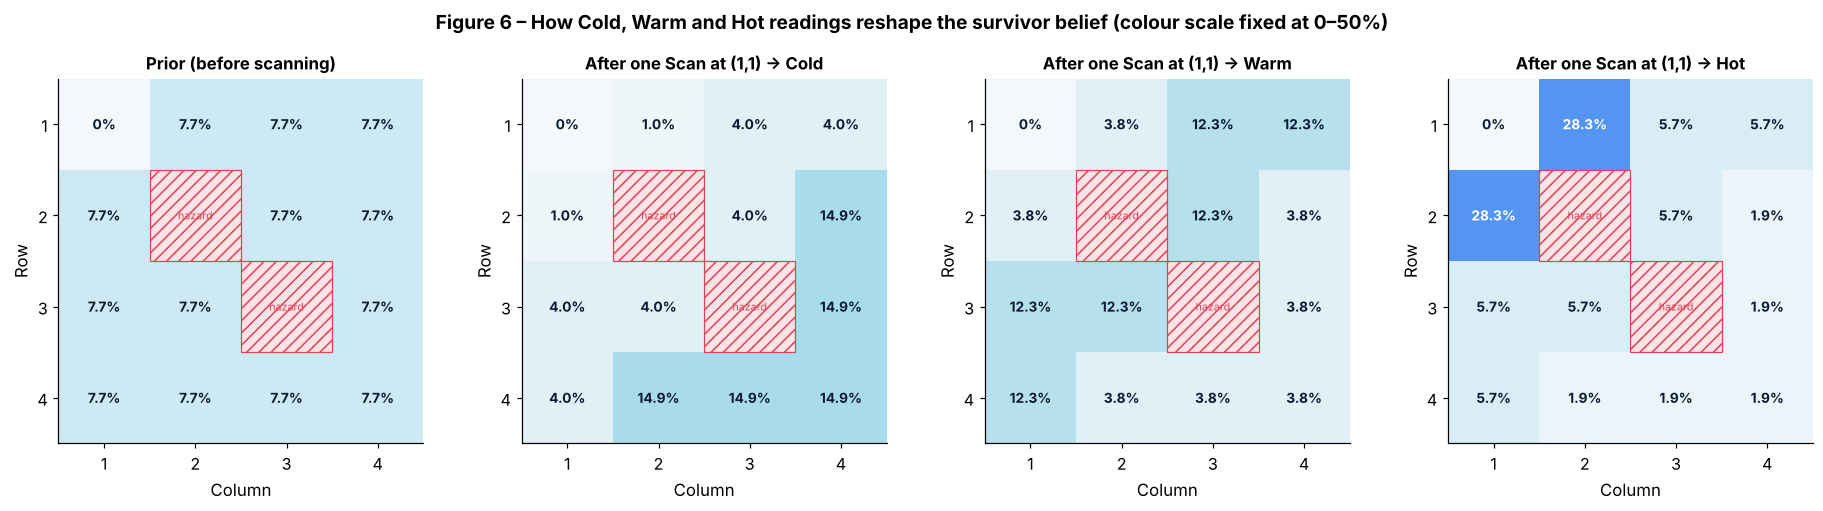

Cold : survivor entropy 3.70 → 3.28 bits; most likely cell (2,4) (14.9%)
Warm : survivor entropy 3.70 → 3.48 bits; most likely cell (1,3) (12.3%)
Hot  : survivor entropy 3.70 → 2.98 bits; most likely cell (1,2) (28.3%)


In [10]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.3))
prob_heatmap(axes[0], b0.survivor_marginal(), "Prior (before scanning)", cbar=False, vmax=0.5, fontsize=9)
for ax, o in zip(axes[1:], [OBS_COLD, OBS_WARM, OBS_HOT]):
    prob_heatmap(ax, b0.update(SCAN, o).survivor_marginal(), f"After one Scan at (1,1) → {OBS_NAMES[o]}",
                 cbar=False, vmax=0.5, fontsize=9)
fig.suptitle("Figure 6 – How Cold, Warm and Hot readings reshape the survivor belief (colour scale fixed at 0–50%)",
             fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()
for o in [OBS_COLD, OBS_WARM, OBS_HOT]:
    b1 = b0.update(SCAN, o)
    cell, p = b1.map_survivor()
    print(f"{OBS_NAMES[o]:5s}: survivor entropy {b0.survivor_entropy():.2f} → {b1.survivor_entropy():.2f} bits; most likely cell {fmt_cell(cell)} ({p:.1%})")

*Interpretation.* **Hot** concentrates mass on the two adjacent cells (2,1) and (1,2). **Cold** shifts it to the far cells at distance ≥ 4. **Warm** favours the middle ring. Because every cell in a ring shares the same likelihood, one scan cannot separate cells within a ring, which is why the robot needs to scan from more than one position.

### Belief evolution across movements and repeated scans
The following scripted sequence includes **successful and failed movement**. The observations are drawn from the simulator, with the survivor at (4,4). It shows how scans taken at different positions triangulate the survivor, and how unobserved movement outcomes spread the robot belief.

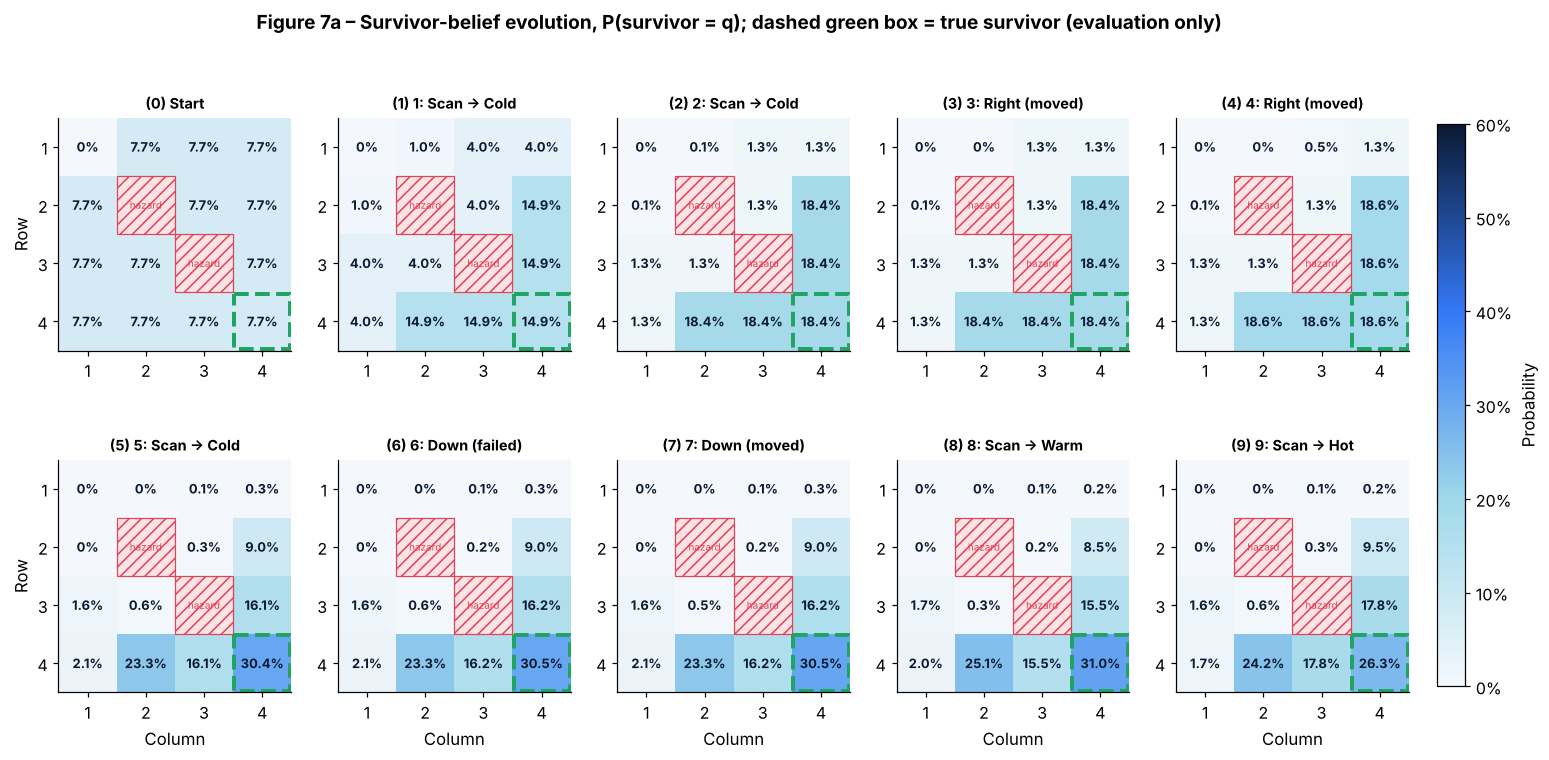

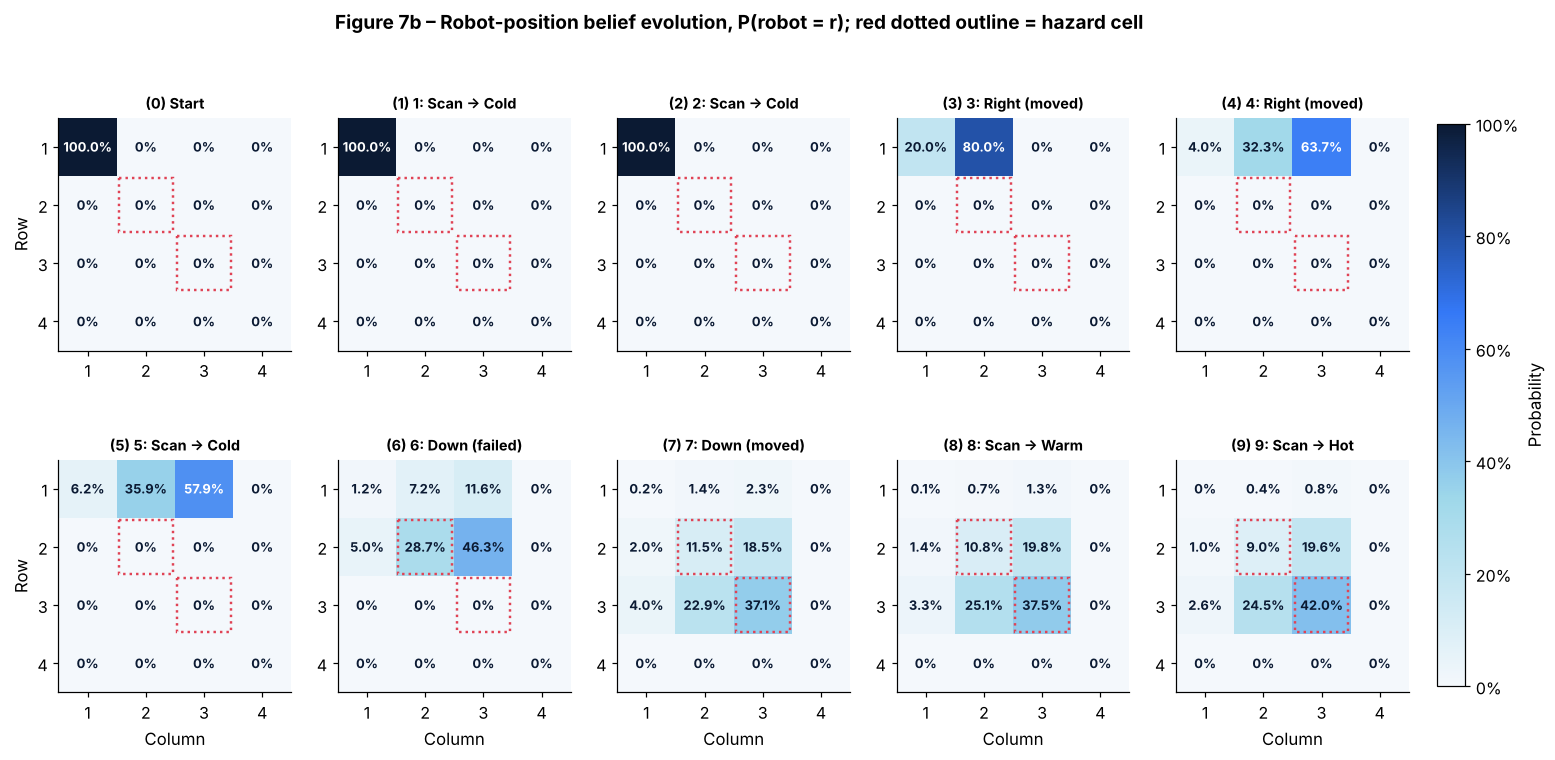

Simulator outcomes: [('Scan', 'Scan (stationary)', 'Cold'), ('Scan', 'Scan (stationary)', 'Cold'), ('Right', 'Moved', 'None'), ('Right', 'Moved', 'None'), ('Scan', 'Scan (stationary)', 'Cold'), ('Down', 'Failed (debris)', 'None'), ('Down', 'Moved', 'None'), ('Scan', 'Scan (stationary)', 'Warm'), ('Scan', 'Scan (stationary)', 'Hot')]


In [11]:
env_demo = RescueBotEnv(cfg, seed=11)
script = [SCAN, SCAN, RIGHT, RIGHT, SCAN, DOWN, DOWN, SCAN, SCAN]
b = Belief.initial(model)
snaps = [("Start", b, None)]
for a in script:
    res = env_demo.step(a)
    o = {v: k for k, v in OBS_NAMES.items()}[res.observation]
    b = b.update(a, o, rescued=res.rescued)
    snaps.append((f"{res.step}: {res.action}" + (f" → {res.observation}" if a == SCAN else f" ({res.outcome.split(' ')[0].lower()})"), b, res))

def snapshot_grid(kind, title, vmax):
    n = len(snaps); ncol = int(np.ceil(n / 2))
    fig, axes = plt.subplots(2, ncol, figsize=(3.3 * ncol, 7.4))
    for k, ax in enumerate(axes.ravel()):
        if k >= n:
            ax.axis("off"); continue
        lab, bb, res = snaps[k]
        if kind == "survivor":
            im = prob_heatmap(ax, bb.survivor_marginal(), f"({k}) {lab}", cbar=False, vmax=vmax, truth=cfg.survivor, fontsize=8.5)
        else:
            im = prob_heatmap(ax, bb.robot_marginal(), f"({k}) {lab}", cbar=False, vmax=vmax, fontsize=8.5, robot=True)
        ax.title.set_fontsize(9.5)
        if k % ncol: ax.set_ylabel("")
        if k < ncol: ax.set_xlabel("")
    cb = fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.02, pad=0.02)
    cb.set_label("Probability"); cb.formatter = matplotlib.ticker.PercentFormatter(1.0, decimals=0); cb.update_ticks()
    fig.suptitle(title, fontweight="bold", fontsize=12.5)
    plt.show()

snapshot_grid("survivor", "Figure 7a – Survivor-belief evolution, P(survivor = q); dashed green box = true survivor (evaluation only)", 0.6)
snapshot_grid("robot", "Figure 7b – Robot-position belief evolution, P(robot = r); red dotted outline = hazard cell", 1.0)
print("Simulator outcomes:", [(s.action, s.outcome, s.observation) for s in env_demo.history])

In [12]:
outs = [s.outcome for s in env_demo.history]
failed = [i + 1 for i, s in enumerate(env_demo.history) if s.outcome.startswith("Failed")]
display(Markdown(
    f"*Interpretation (generated from this run).* Survivor entropy fell from **{snaps[0][1].survivor_entropy():.2f}** to "
    f"**{snaps[-1][1].survivor_entropy():.2f} bits**, and the most likely survivor cell is now "
    f"**{fmt_cell(snaps[-1][1].map_survivor()[0])}** ({snaps[-1][1].map_survivor()[1]:.0%}). "
    f"Robot-position entropy rose from 0 to **{snaps[-1][1].robot_entropy():.2f} bits**: movement outcomes are never observed, "
    f"so each move splits the robot belief 80/20"
    + (f" (the simulator's debris failure at step(s) {failed} is invisible to the robot)" if failed else "")
    + ". The bottom row shows the robot's own position becoming uncertain: there is a 'hidden state' about the robot itself, "
      "not only about the survivor."))

*Interpretation (generated from this run).* Survivor entropy fell from **3.70** to **2.50 bits**, and the most likely survivor cell is now **(4,4)** (26%). Robot-position entropy rose from 0 to **2.09 bits**: movement outcomes are never observed, so each move splits the robot belief 80/20 (the simulator's debris failure at step(s) [6] is invisible to the robot). The bottom row shows the robot's own position becoming uncertain: there is a 'hidden state' about the robot itself, not only about the survivor.

## 10. RescueBot simulation

**Requirement 3.** `RescueBotEnv` is the ground-truth simulator, with methods `reset(seed)`, `step(action)`, `get_observation()`, `is_terminal()` and `get_state_for_evaluation()`. `MissionRunner` runs the decision loop at every step:

1. take the current belief → 2. ask the policy, passing the belief and the number of decisions left before the deadline → 3. choose the action → 4. execute it in the simulator → 5. receive the observation (Scan only) → 6. Bayes-update the belief → 7. record reward and cumulative reward → 8. check for rescue → repeat until rescue or 30 steps.

**Information hiding is enforced, not just promised.** While the policy is deciding, `MissionRunner` *locks* the simulator, and any read of the hidden state raises `HiddenStateAccessError` (Section 12 runs an automated leakage test). Ground truth is recorded *after* each step and only for evaluation and plotting.

Below, a full mission is run with the default POMCP planner. The environment seed (2026) and planner seed (7) were fixed **before** looking at the outcome.

In [13]:
demo = MissionRunner(cfg, POMCPPlanner(model, seed=7), env_seed=2026)
t0 = time.time(); demo.run(); elapsed = time.time() - t0
hist = demo.history_frame()
show = hist[["step", "action", "outcome", "observation", "reward", "cumulative_reward", "true_robot", "est_robot",
             "est_robot_prob", "est_survivor", "est_survivor_prob", "survivor_entropy", "robot_entropy"]]
display(show.style.format({"est_robot_prob": "{:.0%}", "est_survivor_prob": "{:.0%}", "survivor_entropy": "{:.2f}",
                           "robot_entropy": "{:.2f}", "reward": "{:+.0f}", "cumulative_reward": "{:+.0f}"}).hide(axis="index"))
last = demo.records[-1]
print(f"Mission {'SUCCESS' if last['rescued'] else 'NOT COMPLETED'} in {last['step']} steps, cumulative reward {last['cumulative_reward']:+.0f}, "
      f"planning time {elapsed:.2f}s ({elapsed/last['step']*1000:.0f} ms per decision)")
hist.drop(columns=[]).to_json("results/demo_history.json", orient="records", indent=1)

step,action,outcome,observation,reward,cumulative_reward,true_robot,est_robot,est_robot_prob,est_survivor,est_survivor_prob,survivor_entropy,robot_entropy
0,nan,Mission start,None,+0,+0,"(1,1)","(1,1)",100%,"(1,2)",8%,3.70,-0.00
1,Scan,Scan (stationary),Cold,+0,+0,"(1,1)","(1,1)",100%,"(2,4)",15%,3.28,-0.00
2,Right,Moved,None,-10,-10,"(1,2)","(1,2)",80%,"(2,4)",15%,3.25,0.73
3,Up,Blocked by boundary,None,-10,-20,"(1,2)","(1,2)",80%,"(2,4)",15%,3.25,0.73
4,Scan,Scan (stationary),Cold,+0,-20,"(1,2)","(1,2)",75%,"(3,4)",23%,2.79,0.81
5,Scan,Scan (stationary),Cold,+0,-20,"(1,2)","(1,2)",73%,"(3,4)",26%,2.45,0.84
6,Scan,Scan (stationary),Warm,+0,-20,"(1,2)","(1,2)",75%,"(3,4)",23%,2.73,0.81
7,Right,Failed (debris),None,-10,-30,"(1,2)","(1,3)",60%,"(3,4)",23%,2.72,1.19
8,Scan,Scan (stationary),Cold,+0,-30,"(1,2)","(1,3)",51%,"(4,4)",36%,2.47,1.30
9,Scan,Scan (stationary),Warm,+0,-30,"(1,2)","(1,3)",58%,"(4,4)",26%,2.63,1.21


Mission SUCCESS in 23 steps, cumulative reward +10, planning time 2.39s (104 ms per decision)


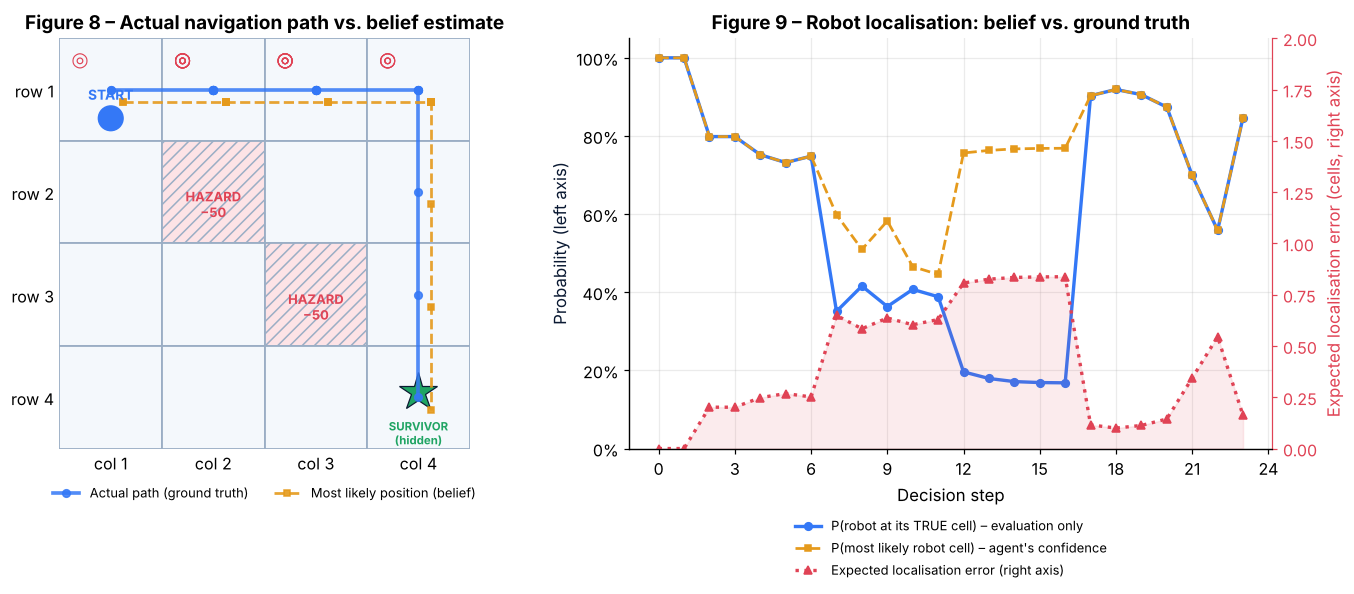

*Interpretation (generated).* Debris failures occurred at step(s) **[7, 12]**. Whether or not a move fails, the robot cannot confirm it, so its belief keeps 20% on 'still here' after every move; the most likely robot cell differed from the true cell at step(s) **[7, 8, 9, 10, 11, 12, 13, 14, 15, 16]**. Red ◎ marks scan locations; the robot scanned from **4** different cell(s) ((1,1), (1,2), (1,3), (1,4)), and readings from different positions are what triangulate the survivor. At step(s) [3] the robot moved into the grid boundary (−10 points each). At step(s) [3] it bought no information, because the robot already knew it was on that edge. That is a wasted move: Monte Carlo planning at 800 simulations is noisy (see the decision-consistency check in Section 11).

In [14]:
path = [r["true_robot"] for r in demo.records]
est = [r["est_robot"] for r in demo.records]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), gridspec_kw={"width_ratios": [1, 1.2]})
draw_grid(axes[0], cfg, "Figure 8 – Actual navigation path vs. belief estimate", path=path, est_path=est, annotate_coords=False)
for k, (p, rec) in enumerate(zip(path, demo.records)):
    if rec["action"] == "Scan":
        axes[0].text(p[1] + 0.5 - 0.3, p[0] + 0.5 - 0.3, "◎", fontsize=13, color=PAL["red"], ha="center", va="center")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=2, fontsize=8.5)
ax = axes[1]
steps = [r["step"] for r in demo.records]
ax.plot(steps, [r["p_true_robot"] for r in demo.records], "-o", color=PAL["blue"], lw=2.2, ms=5, label="P(robot at its TRUE cell) – evaluation only")
ax.plot(steps, [r["est_robot_prob"] for r in demo.records], "--s", color=PAL["amber"], lw=1.8, ms=4, label="P(most likely robot cell) – agent's confidence")
ax.set_ylim(0, 1.05); ax.set_xlabel("Decision step"); ax.set_ylabel("Probability (left axis)", color=PAL["navy"])
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
ax2 = ax.twinx()
err = [r["expected_localisation_error"] for r in demo.records]
ax2.fill_between(steps, err, step=None, color=PAL["red"], alpha=0.10)
ax2.plot(steps, err, ":", color=PAL["red"], lw=2.2, marker="^", ms=5, label="Expected localisation error (right axis)")
ax2.set_ylabel("Expected localisation error (cells, right axis)", color=PAL["red"]); ax2.tick_params(axis="y", colors=PAL["red"])
ax2.spines["right"].set_visible(True); ax2.spines["right"].set_color(PAL["red"]); ax2.grid(False)
ax2.set_ylim(0, max(2.0, max(err) * 1.25))
ax.set_title("Figure 9 – Robot localisation: belief vs. ground truth")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=1, fontsize=8.5)
plt.tight_layout(); plt.show()
mism = [r["step"] for r in demo.records if r["est_robot"] != r["true_robot"]]
blocked = [r["step"] for r in demo.records if r["outcome"] == "Blocked by boundary"]
fails = [r["step"] for r in demo.records if r["outcome"].startswith("Failed")]
scan_cells = sorted({fmt_cell(r["true_robot"]) for r in demo.records if r["action"] == "Scan"})
txt = (f"*Interpretation (generated).* Debris failures occurred at step(s) **{fails or 'none'}**. Whether or not a move fails, the robot "
       f"cannot confirm it, so its belief keeps 20% on 'still here' after every move; the most likely robot cell differed from the true cell "
       f"at step(s) **{mism or 'none'}**. Red ◎ marks scan locations; the robot scanned from "
       f"**{len(scan_cells)}** different cell(s) ({', '.join(scan_cells)}), and readings from different positions are what triangulate the survivor.")
if blocked:
    drops = [k for k in blocked if demo.records[k]["robot_entropy"] < demo.records[k - 1]["robot_entropy"] - 1e-9]
    nodrop = [k for k in blocked if k not in drops]
    txt += f" At step(s) {blocked} the robot moved into the grid boundary (−10 points each)."
    if drops:
        txt += (f" At step(s) {drops} this acted as a localisation fix: the robot then knows it is on the edge whatever happened before, "
                "and its robot entropy dropped (Figure 11).")
    if nodrop:
        txt += (f" At step(s) {nodrop} it bought no information, because the robot already knew it was on that edge. That is a wasted "
                "move: Monte Carlo planning at 800 simulations is noisy (see the decision-consistency check in Section 11).")
display(Markdown(txt))

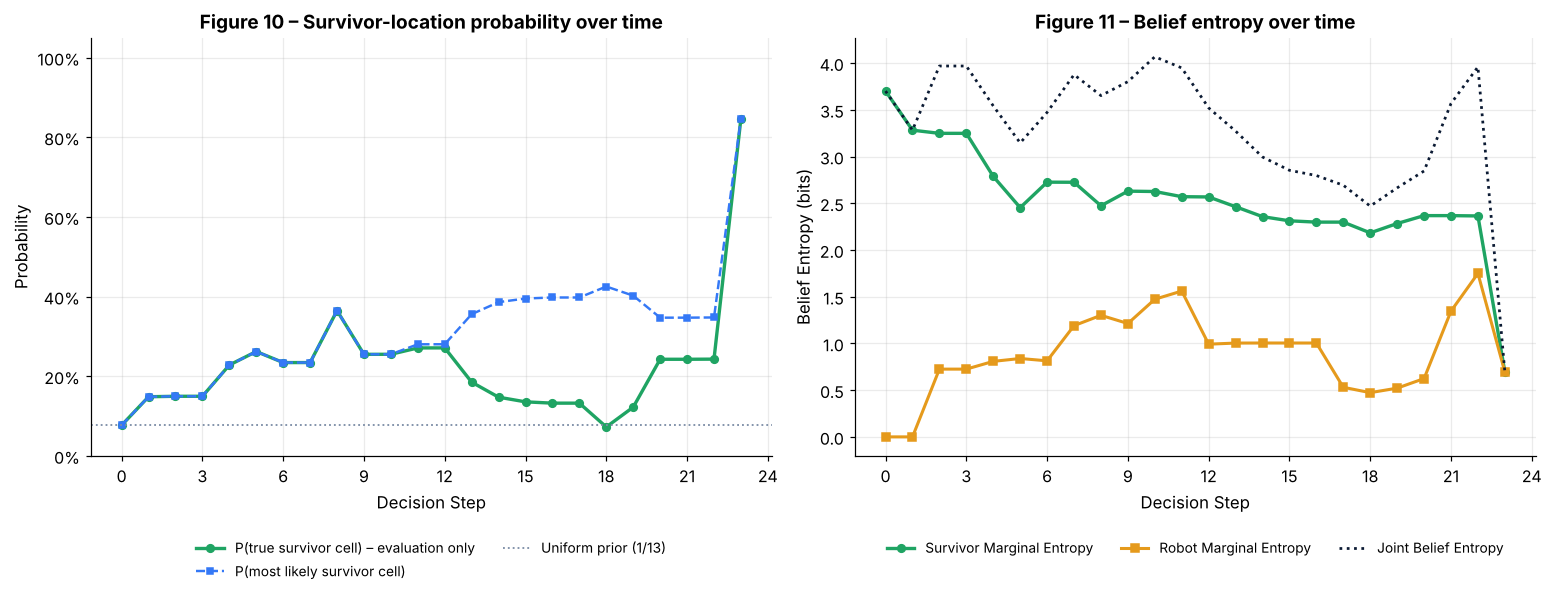

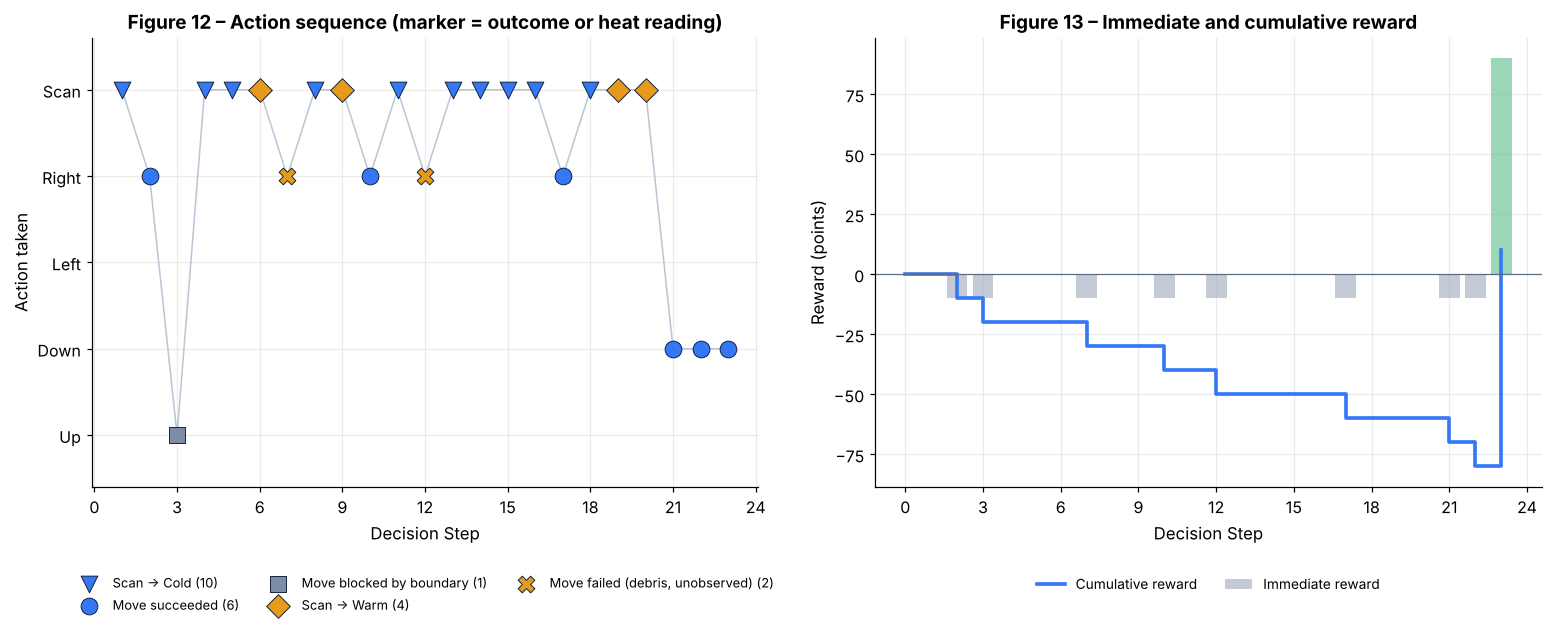

In [15]:
st = np.array(steps)
legend_below = dict(loc="upper center", bbox_to_anchor=(0.5, -0.17), frameon=False, fontsize=9)
# ---------------- Figures 10 and 11 (legends below each plot, outside the data region)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.3), layout="constrained")
ax = axes[0]
ax.plot(st, [r["p_true_survivor"] for r in demo.records], "-o", color=PAL["green"], lw=2.2, ms=5, label="P(true survivor cell) – evaluation only")
ax.plot(st, [r["est_survivor_prob"] for r in demo.records], "--s", color=PAL["blue"], lw=1.6, ms=4, label="P(most likely survivor cell)")
ax.axhline(1/13, color=PAL["grey"], ls=":", lw=1.2, label="Uniform prior (1/13)")
ax.set_ylim(0, 1.05); ax.set_xlabel("Decision Step"); ax.set_ylabel("Probability")
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Figure 10 – Survivor-location probability over time")
ax.legend(ncol=2, **legend_below)
ax = axes[1]
ax.plot(st, [r["survivor_entropy"] for r in demo.records], "-o", color=PAL["green"], lw=2.2, ms=5, label="Survivor Marginal Entropy")
ax.plot(st, [r["robot_entropy"] for r in demo.records], "-s", color=PAL["amber"], lw=2.0, ms=5, label="Robot Marginal Entropy")
ax.plot(st, [r["joint_entropy"] for r in demo.records], ":", color=PAL["navy"], lw=1.8, label="Joint Belief Entropy")
ax.set_xlabel("Decision Step"); ax.set_ylabel("Belief Entropy (bits)")
ax.set_ylim(bottom=min(0, ax.get_ylim()[0]))
ax.set_title("Figure 11 – Belief entropy over time")
ax.legend(ncol=3, **legend_below)
for ax in axes:
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
plt.show()

# ---------------- Figures 12 and 13
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), layout="constrained")
# action sequence: colour = outcome / heat reading (no overlapping text labels)
ax = axes[0]
amap = {"Up": 0, "Down": 1, "Left": 2, "Right": 3, "Scan": 4}
outcome_style = {"Moved": (PAL["blue"], "o", "Move succeeded"), "Failed": (PAL["amber"], "X", "Move failed (debris, unobserved)"),
                 "Blocked": (PAL["grey"], "s", "Move blocked by boundary"),
                 "Cold": ("#3478F6", "v", "Scan → Cold"), "Warm": ("#E59A1C", "D", "Scan → Warm"), "Hot": (PAL["red"], "^", "Scan → Hot")}
groups = {}
for t, rec in zip(st[1:], demo.records[1:]):
    key = rec["observation"] if rec["action"] == "Scan" else rec["outcome"].split(" ")[0]
    groups.setdefault(key, []).append((t, amap[rec["action"]]))
for key, pts in groups.items():
    col, mk, lab = outcome_style[key]
    ax.scatter([p_[0] for p_ in pts], [p_[1] for p_ in pts], color=col, marker=mk, s=120, edgecolor=PAL["navy"], lw=0.6,
               zorder=3, label=f"{lab} ({len(pts)})")
ax.plot(st[1:], [amap[r["action"]] for r in demo.records[1:]], color="#B9C6D6", lw=1, zorder=1)
ax.set_yticks(range(5), list(amap)); ax.set_ylim(-0.6, 4.6)
ax.set_xlabel("Decision Step"); ax.set_ylabel("Action taken")
ax.set_title("Figure 12 – Action sequence (marker = outcome or heat reading)")
ax.legend(ncol=3, **{**legend_below, "fontsize": 8.5})
# cumulative reward
ax = axes[1]
ax.step(st, [r["cumulative_reward"] for r in demo.records], where="post", color=PAL["blue"], lw=2.4, label="Cumulative reward")
ax.bar(st[1:], [r["reward"] for r in demo.records[1:]], color=[PAL["green"] if r["reward"] > 0 else (PAL["red"] if r["reward"] < -10 else PAL["grey"]) for r in demo.records[1:]],
       alpha=0.45, label="Immediate reward")
ax.axhline(0, color="#5B6B82", lw=0.8)
ax.set_xlabel("Decision Step"); ax.set_ylabel("Reward (points)")
ax.set_title("Figure 13 – Immediate and cumulative reward")
ax.legend(ncol=2, **legend_below)
for ax in axes:
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
plt.show()

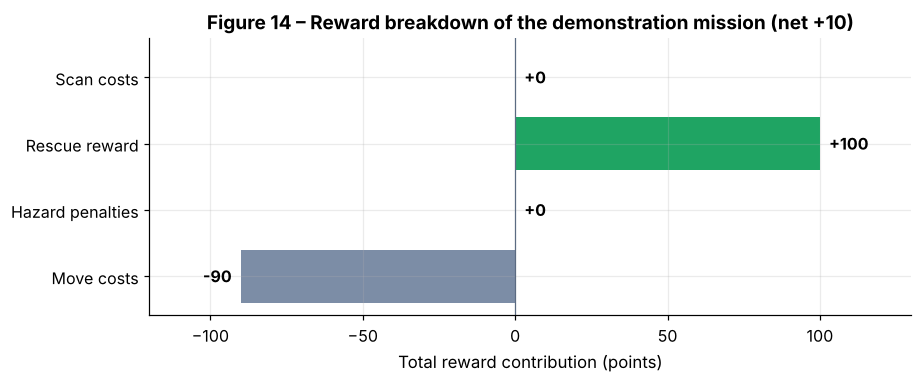

*Interpretation (generated).* The mission used **9 moves** (−90 points) and **14 free scans**, entered **0** hazard cells and earned the rescue reward. The scans are what let the robot commit to the right corner of the grid without paying for exploratory moves.

In [16]:
h = pd.DataFrame(demo.records[1:])
comp = h[["move_cost", "hazard", "rescue", "scan_cost"]].sum()
fig, ax = plt.subplots(figsize=(8.5, 3.6))
labels = ["Move costs", "Hazard penalties", "Rescue reward", "Scan costs"]
vals = comp.values
colors = [PAL["grey"], PAL["red"], PAL["green"], PAL["amber"]]
bars = ax.barh(labels, vals, color=colors)
for b_, v in zip(bars, vals):
    ax.text(v + (3 if v >= 0 else -3), b_.get_y() + b_.get_height() / 2, f"{v:+.0f}", va="center",
            ha="left" if v >= 0 else "right", fontweight="bold")
ax.axvline(0, color="#5B6B82", lw=0.8); ax.set_xlabel("Total reward contribution (points)")
ax.set_xlim(min(vals.min(), 0) - 30, max(vals.max(), 0) + 30)
ax.set_title(f"Figure 14 – Reward breakdown of the demonstration mission (net {vals.sum():+.0f})")
plt.tight_layout(); plt.show()
n_moves = (h["action"] != "Scan").sum(); n_scans = (h["action"] == "Scan").sum()
display(Markdown(f"*Interpretation (generated).* The mission used **{n_moves} moves** (−{10*n_moves} points) and **{n_scans} free scans**, "
                 f"entered **{int((h['hazard'] < 0).sum())}** hazard cells and {'earned' if comp['rescue'] > 0 else 'did not earn'} the rescue reward. "
                 "The scans are what let the robot commit to the right corner of the grid without paying for exploratory moves."))

## 11. Monte Carlo planning: POMCP

**Requirement 4.** Exact POMDP value iteration over the continuous belief simplex is intractable. POMCP (Silver & Veness, 2010) instead estimates action values by **Monte Carlo tree search over action–observation histories**, applying the UCT algorithm (Kocsis & Szepesvári, 2006) and the UCB1 bandit rule (Auer et al., 2002) to histories rather than states:

```
SEARCH(b, H_rem):                 # H_rem = H_mission − t  (real decisions left before the deadline)
    H_search ← min(H_configured, H_rem)
    repeat n_simulations times:
        s ~ b                     # a HYPOTHETICAL world sampled from the belief
        SIMULATE(s, root, d=0)
    return argmax_a Q(root, a)

SIMULATE(s, h, d):
    if d ≥ H_search or h not in tree:  (add h)  return ROLLOUT(s, b_h, d)
    a ← argmax_a Q(h,a) + c·sqrt(ln N(h) / N(h,a))       # UCB1 on history statistics (untried actions first)
    (s', o, r) ~ G(s, a)                                  # generative model = T, Z, R  (uses the hidden s)
    R ← r                                  if s' terminal (rescue)
    R ← r + γ·SIMULATE(s', h·a·o, d+1)     otherwise     # child node stores b_{h·a·o} = Bayes(b_h, a, o)
    N(h) += 1;  N(h,a) += 1;  Q(h,a) += (R − Q(h,a)) / N(h,a)
    return R

ROLLOUT(s, b, d):                 # belief-tracked rollout, runs until total depth H_rem
    while d < H_rem:
        a ← π_roll(b)             # chosen from the BELIEF only – never from s
        (s, o, r) ~ G(s, a);  accumulate γ^k · r;  stop if terminal
        b ← Bayes(b, a, None)     # predict with T, condition on "survivor not reached", normalise
        d ← d + 1
```

**Implementation choices (all configurable):**

| Parameter | Default | Note |
|---|---|---|
| Simulations per decision | 800 | |
| Search (tree) depth | 10, capped at the remaining mission steps | $H_{search} = \min(10,\ 30 - t)$ |
| Rollout limit | the remaining mission steps $H_{rem} = 30 - t$ | depth already used in the tree is counted, so no simulated reward is collected after the real deadline |
| UCB exploration constant c | **150** | selection rule below; swept in Section 14 (5 – 300) |
| Discount γ | 0.95 | |
| Observation branching | Move → `None` (or terminal), Scan → Cold/Warm/Hot | at most 7 non-terminal successor histories per node; a rescue creates no child |
| Root belief | **exact** Bayes posterior, re-planned every step | *receding-horizon POMCP* (the PO-UCT form for which the paper states convergence) |
| Rollout policy | **belief-tracked** | see below |

**Information discipline inside the search.** The sampled hidden state $s=(r,q)$ is a *hypothesis* drawn from the belief, never the simulator's truth. It is used **only** by the generative model G to produce transitions, readings, rewards and the terminal (rescue) event. Every *action* the search chooses is a function of the simulated history alone. In the tree, UCB uses only the node's statistics. Beyond the tree, the rollout policy $\pi_{roll}$ reads only the history's exact posterior $b_h$, which each node stores (one Bayes update per new node) and which the rollout keeps updating step by step.

**Rollout policy (documented choice).** $\pi_{roll}(b)$ targets the currently most likely survivor cell. It then takes the move with the lowest *expected* hazard-aware cost-to-go, averaged over the robot-position marginal and the 80/20 movement model (10% uniformly random moves), and never scans. After each simulated move the belief is updated by the Bayes filter with the *None* observation and the "survivor not reached" evidence. Cells the robot has probably visited therefore lose probability and the target moves on: a belief-driven search sweep that is valid even when the robot is unsure where it is. Two alternatives are implemented for comparison only:
* `oracle`: walks from the *sampled* robot cell to the *sampled* survivor. It reads hidden information, so it is **not deployable**, and it is optimistic.
* `random`: uniform random actions.

Automated tests (`tests/test_planner.py`) confirm the following. Changing the hidden robot or survivor cell while keeping the agent's information fixed leaves the belief rollout's actions unchanged (the oracle's change). The rollout's belief updates match `Belief.update` exactly. For remaining horizons of 1, 2, 5 and 10, no simulated step occurs beyond the deadline.

**Choice of the exploration constant.** The selection rule was fixed *before* looking at evaluation results: *choose the c with the highest mean discounted return, the planner's own objective, on development seeds (base seed 77, 40 episodes per value) over c ∈ {5, 20, 50, 100, 150, 300}*. That sweep is reproduced in full in Section 14 (the `pomcp.exploration` rows), and the cell there re-checks which value wins. The rule selects **c = 150**, an empirically tuned value. Its scale is broadly consistent with Silver & Veness's reward-range guidance c ≈ R_hi − R_lo (returns here span roughly −150 to +100 points), but it was *not* computed with that procedure, which uses separate runs with c = 0. c = 20 was an earlier candidate, tested in the sweep and not selected: it under-explores, letting the first lucky rollout dominate the search. A larger c is not uniformly better, though. c = 150 is chosen on discounted return and is *not* claimed to maximise every metric; the sweep shows the trade-off with success rate and cumulative reward. For example, c = 100 had a higher success-rate point estimate (90.0% vs 87.5%, overlapping 95% Wilson intervals) but a lower mean discounted return. All results in Sections 12–13 use **different** seeds (base seed 2026), so the choice is not tuned on the reported episodes.

**No optimality guarantee.** With a finite budget POMCP is an approximation. Its convergence result holds only as the number of simulations goes to infinity.

In [17]:
planner = POMCPPlanner(model, seed=1)
t0 = time.time(); dec = planner.select_action(b0, steps_remaining=cfg.max_steps); dt = time.time() - t0
qv = pd.DataFrame({"Q(root, a) – estimated discounted return": dec.info["q_values"], "visits N(root, a)": dec.info["visits"]})
display(qv.style.format({"Q(root, a) – estimated discounted return": "{:+.2f}"}))
print(f"Chosen action at the initial belief: {ACTION_NAMES[dec.action]} | tree nodes: {dec.info['tree_nodes']} | time: {dt*1000:.0f} ms")

# Q-values at three informative beliefs
beliefs = {"Initial belief": b0, "After Scan → Hot": b0.update(SCAN, OBS_HOT), "After Scan → Cold": b0.update(SCAN, OBS_COLD)}
fig = go.Figure(); chosen = {}
rem = {"Initial belief": 30, "After Scan → Hot": 29, "After Scan → Cold": 29}   # decisions left before the deadline
for (name, bb), col in zip(beliefs.items(), [PAL["grey"], PAL["red"], PAL["blue"]]):
    d_ = POMCPPlanner(model, n_simulations=3000, seed=5).select_action(bb, steps_remaining=rem[name])
    q = d_.info["q_values"]; chosen[name] = (ACTION_NAMES[d_.action], max(q.values()), q)
    fig.add_bar(name=f"{name} → chooses {ACTION_NAMES[d_.action]}", x=list(q), y=list(q.values()), marker_color=col,
                text=[f"{v:+.1f}" for v in q.values()], textposition="outside")
fig.update_layout(title="Figure 15 – POMCP action-value estimates Q(b, a) at three beliefs (3,000 simulations)",
                  xaxis_title="Available action", yaxis_title="Estimated expected return (reward points)",
                  template="plotly_white", barmode="group", height=450, legend=dict(orientation="h", y=-0.22),
                  margin=dict(t=70, l=70, r=20, b=110))
fig.show()
lines = [f"* **{k}**: best estimated value {v[1]:+.1f} → chooses **{v[0]}**" for k, v in chosen.items()]
txt = "*Interpretation (generated).*\n" + "\n".join(lines) + "\n\n"
if chosen["After Scan → Hot"][1] > chosen["Initial belief"][1] > chosen["After Scan → Cold"][1]:
    txt += ("The estimated value of the best action rises after *Hot*, because a rescue may be close, and falls after *Cold*, "
            "because the survivor is probably 4+ cells away. ")
if len({v[0] for v in chosen.values()}) > 1:
    txt += "The chosen action itself changes with the evidence: the same robot in the same cell acts differently depending on what it has observed."
else:
    txt += ("Here the chosen action is the same at all three beliefs (one scan is rarely decisive), but the value estimates differ, "
            "and those values decide when the robot stops scanning and commits to a direction.")
display(Markdown(txt))

,"Q(root, a) – estimated discounted return","visits N(root, a)"
Up,-82.99,140
Down,-87.23,110
Left,-91.96,87
Right,-90.04,97
Scan,-70.71,365


Chosen action at the initial belief: Scan | tree nodes: 737 | time: 159 ms


*Interpretation (generated).*
* **Initial belief**: best estimated value -60.1 → chooses **Scan**
* **After Scan → Hot**: best estimated value -22.6 → chooses **Scan**
* **After Scan → Cold**: best estimated value -62.0 → chooses **Scan**

The estimated value of the best action rises after *Hot*, because a rescue may be close, and falls after *Cold*, because the survivor is probably 4+ cells away. Here the chosen action is the same at all three beliefs (one scan is rarely decisive), but the value estimates differ, and those values decide when the robot stops scanning and commits to a direction.

*Interpretation.* These bars are **estimates of expected discounted return** from POMCP's search tree, not rewards actually received. The interpretation printed under the chart compares the three beliefs.

**Decision consistency.** POMCP is stochastic, so re-planning from the same belief with different random seeds may select different actions when two actions have close values. The cell below measures how often the most common action is chosen.

In [18]:
# rebuild the demonstration beliefs step by step from its recorded actions/observations
bb = Belief.initial(model); cons_beliefs = [bb]
for rec in demo.records[1:-1]:
    a = {v: k for k, v in ACTION_NAMES.items()}[rec["action"]]; o = {v: k for k, v in OBS_NAMES.items()}[rec["observation"]]
    bb = bb.update(a, o); cons_beliefs.append(bb)
cons = decision_consistency(model, cons_beliefs, n_repeats=8, seed=100)
display(cons)
print(f"Mean decision consistency over {len(cons)} demonstration beliefs: {cons['agreement'].mean():.0%} "
      f"(1.0 = the same action under every planner seed)")
cons.to_csv("results/decision_consistency.csv", index=False)

,step,modal_action,agreement,actions
0,0,Scan,0.875,"Scan, Right, Scan, Scan, Scan, Scan, Scan, Scan"
1,1,Scan,0.875,"Scan, Right, Scan, Scan, Scan, Scan, Scan, Scan"
2,2,Right,0.500,"Left, Scan, Right, Right, Right, Scan, Right, ..."
3,3,Right,0.625,"Scan, Right, Scan, Right, Right, Right, Right,..."
4,4,Right,0.625,"Scan, Right, Right, Scan, Right, Scan, Right, ..."
5,5,Scan,0.750,"Scan, Right, Scan, Scan, Scan, Scan, Right, Scan"
6,6,Right,0.875,"Scan, Right, Right, Right, Right, Right, Right..."
7,7,Right,0.500,"Scan, Right, Right, Scan, Scan, Right, Right, ..."
8,8,Right,0.750,"Right, Right, Right, Scan, Right, Scan, Right,..."
9,9,Scan,0.625,"Right, Scan, Scan, Scan, Scan, Right, Right, Scan"


Mean decision consistency over 23 demonstration beliefs: 72% (1.0 = the same action under every planner seed)


## 12. Alternative policy comparison

| Policy | Uses | Deployable? | Idea |
|---|---|---|---|
| **POMCP** | belief + model | ✔ | Online Monte Carlo tree search (Section 11) |
| **Risk-aware heuristic** (belief heuristic in the spirit of Cassandra, Kaelbling & Kurien, 1996; *not* a pure MLS policy, see note) | belief + model | ✔ | Scan while P(most likely survivor cell) < 50% (at most 2 scans in a row). Otherwise move toward that cell, minimising the expected hazard-aware cost-to-go averaged over the robot-position belief |
| **QMDP** (Littman, Cassandra & Kaelbling, 1995) | belief + MDP Q-values | ✔ | $\arg\max_a \sum_s b(s) Q_{MDP}(s,a)$. Assumes uncertainty disappears after one step, so it can never value Scan for its information |
| **Random** | seed only | ✔ | Uniform over the 5 actions (reproducible seed) |
| **Clairvoyant** | **true** robot + survivor | ✘ *idealised reference* | Optimal MDP policy from value iteration. Shows the value of perfect information |

**Risk-aware heuristic vs. MLS.** The classic *Most Likely State* (MLS) policy (Cassandra, Kaelbling & Kurien, 1996) picks the single most probable *joint* hidden state and executes the MDP-optimal action for it, ignoring every other hypothesis. The risk-aware heuristic implemented here is different in three ways. It **scans** while its confidence is low (MLS never deliberately gathers information). It uses the most likely survivor cell only as a *target*, while **averaging the move choice over the whole robot-position belief**. And it charges hazard entries at their full −50 inside its cost-to-go (a safety term). No standalone MLS policy was implemented or evaluated in this project.

**Evaluation protocol.**
* 100 episodes per policy.
* The survivor position is drawn **uniformly from the prior**, so the evaluation covers every possible survivor cell. A separate run uses the fixed (4,4) demonstration scenario.
* **Common random numbers:** episode *i* uses the same survivor cell and the same pre-drawn movement and sensor random numbers for every policy.
* 95% CIs: **Wilson score** intervals for success rates (Wilson, 1927; Brown, Cai & DasGupta, 2001), **percentile bootstrap** (5,000 resamples; Efron & Tibshirani, 1993) for mean cumulative reward, mean discounted return and mean steps, and for paired, seed-matched differences. The remaining metrics (scans, hazard entries, hazard-entry rate, survivor MAP accuracy, entropies, localisation error) are point estimates. No McNemar p-values or multiplicity corrections are computed. This project uses the percentile bootstrap with 5,000 resamples for reproducible interval estimation. No head-to-head comparison against BCa was conducted.

First, the automated **information-leakage checks**.

In [19]:
# 1. The planner-facing model contains no survivor information
assert not hasattr(model, "survivor") and "survivor" not in vars(model)
# 2. A policy that tries to read the simulator's hidden state while deciding is stopped
class SpyPolicy(RandomPolicy):
    def __init__(self, model, env): super().__init__(model, seed=0); self.env = env
    def select_action(self, belief, ground_truth=None, steps_remaining=None):
        self.env.get_state_for_evaluation(); return super().select_action(belief)
runner = MissionRunner(cfg, RandomPolicy(model), env_seed=0); runner.policy = SpyPolicy(model, runner.env)
try:
    runner.step(); leak = "NOT blocked ✘"
except rb.HiddenStateAccessError:
    leak = "blocked ✔"
print("Spy policy reading hidden state during decision:", leak)
# 3. Same belief + same planner seed -> identical decision whatever the true survivor cell
outs = []
for surv in [(3, 3), (0, 3), (2, 0), (3, 0)]:
    m_ = cfg.with_(survivor=surv).public_model()
    d_ = POMCPPlanner(m_, n_simulations=400, seed=9).select_action(Belief.initial(m_).update(SCAN, OBS_WARM), steps_remaining=29)
    outs.append((ACTION_NAMES[d_.action], round(d_.info["q_values"]["Scan"], 6)))
print("POMCP decisions for 4 different TRUE survivor cells:", outs)
assert len(set(outs)) == 1
# 4. Ground-truth inspection between steps (as in instructor mode) does not alter decisions
def run_actions(peek):
    r_ = MissionRunner(cfg, POMCPPlanner(model, n_simulations=200, seed=3), env_seed=9); acts_ = []
    while not r_.done:
        if peek: r_.env.get_state_for_evaluation()
        acts_.append(r_.step()["action"])
    return acts_
assert run_actions(True) == run_actions(False)
print("✔ Leakage checks passed: no policy can read, or is influenced by, the hidden survivor position.")

Spy policy reading hidden state during decision: blocked ✔


POMCP decisions for 4 different TRUE survivor cells: [('Scan', -81.085418), ('Scan', -81.085418), ('Scan', -81.085418), ('Scan', -81.085418)]


✔ Leakage checks passed: no policy can read, or is influenced by, the hidden survivor position.


In [20]:
SPECS = [rb.DEFAULT_POMCP, PolicySpec.of("heuristic"), PolicySpec.of("qmdp"), PolicySpec.of("random"), PolicySpec.of("clairvoyant")]
N_EPISODES = 100
t0 = time.time()
eval_df = evaluate_policies(cfg, SPECS, n_episodes=N_EPISODES, base_seed=2026, survivor_mode="random", n_jobs=N_JOBS)
print(f"Random-survivor evaluation: {len(eval_df)} episodes in {time.time()-t0:.0f}s")
t0 = time.time()
fixed_df = evaluate_policies(cfg, SPECS, n_episodes=50, base_seed=2026, survivor_mode="fixed", n_jobs=N_JOBS)
print(f"Fixed-scenario (survivor (4,4)) evaluation: {len(fixed_df)} episodes in {time.time()-t0:.0f}s")
eval_df.to_json("results/evaluation_episodes.json", orient="records")   # incl. per-step traces (dashboard)
trace_cols = [c_ for c_ in eval_df.columns if c_.startswith("trace_") or c_ == "actions"]
pd.concat([eval_df.drop(columns=trace_cols).assign(experiment="main: survivor from prior"),
           fixed_df.drop(columns=trace_cols).assign(experiment="fixed survivor (4,4)")]).to_csv("results/episode_results.csv", index=False)
fixed_df.to_json("results/evaluation_fixed_episodes.json", orient="records")
summary = summarise_evaluation(eval_df); fixed_summary = summarise_evaluation(fixed_df)
summary.to_csv("results/evaluation_summary.csv", index=False); fixed_summary.to_csv("results/evaluation_fixed_summary.csv", index=False)
cols = ["Policy", "Episodes", "Success rate", "Success 95% CI", "Mean reward", "Reward 95% CI", "Mean discounted return",
        "Mean steps", "Steps to rescue (successes)", "Mean scans", "Hazard-entry rate", "Mean hazard entries",
        "Final survivor entropy (bits)", "Mean robot entropy (bits)", "Survivor MAP accuracy", "Mean localisation error (cells)"]
fmt = {"Success rate": "{:.0%}", "Mean reward": "{:+.1f}", "Mean discounted return": "{:+.1f}", "Mean steps": "{:.1f}",
       "Steps to rescue (successes)": "{:.1f}", "Mean scans": "{:.1f}", "Hazard-entry rate": "{:.0%}", "Mean hazard entries": "{:.2f}",
       "Final survivor entropy (bits)": "{:.2f}", "Mean robot entropy (bits)": "{:.2f}", "Survivor MAP accuracy": "{:.0%}",
       "Mean localisation error (cells)": "{:.2f}"}
display(Markdown("*Column notes:* **Hazard-entry rate** is the share of episodes with at least one hazard entry. **Final survivor entropy** is the "
                 "survivor-belief entropy just before contact (or at the deadline). **Survivor MAP accuracy** is the share of episodes in which the most likely "
                 "survivor cell at that moment was the true cell. *Steps to rescue* averages successful episodes only. The clairvoyant row is a "
                 "non-deployable reference: it acts on the true state and never scans, so its belief metrics describe a passive, uninformed belief."))
display(Markdown("**Table A – survivor drawn from the prior (100 episodes per policy, common random numbers)**"))
display(summary[cols].style.format(fmt).hide(axis="index"))
display(Markdown("**Table B – fixed demonstration scenario, survivor at (4,4) (50 episodes per policy)**"))
display(fixed_summary[cols].style.format(fmt).hide(axis="index"))

Random-survivor evaluation: 500 episodes in 80s


Fixed-scenario (survivor (4,4)) evaluation: 250 episodes in 46s


*Column notes:* **Hazard-entry rate** is the share of episodes with at least one hazard entry. **Final survivor entropy** is the survivor-belief entropy just before contact (or at the deadline). **Survivor MAP accuracy** is the share of episodes in which the most likely survivor cell at that moment was the true cell. *Steps to rescue* averages successful episodes only. The clairvoyant row is a non-deployable reference: it acts on the true state and never scans, so its belief metrics describe a passive, uninformed belief.

**Table A – survivor drawn from the prior (100 episodes per policy, common random numbers)**

Policy,Episodes,Success rate,Success 95% CI,Mean reward,Reward 95% CI,Mean discounted return,Mean steps,Steps to rescue (successes),Mean scans,Hazard-entry rate,Mean hazard entries,Final survivor entropy (bits),Mean robot entropy (bits),Survivor MAP accuracy,Mean localisation error (cells)
POMCP,100,75%,"[0.66, 0.82]",+2.5,"[-11.3, 16.5]",+0.4,17.8,13.7,11.0,7%,0.08,2.11,0.70,61%,0.30
Risk-aware heuristic,100,76%,"[0.67, 0.83]",-11.3,"[-29.4, 6.0]",-6.8,18.2,14.4,10.2,15%,0.15,2.01,0.90,67%,0.43
QMDP,100,0%,"[0.00, 0.04]",+0.0,"[0.0, 0.0]",+0.0,30.0,nan,30.0,0%,0.00,2.12,0.00,33%,0.00
Random,100,51%,"[0.41, 0.61]",-188.4,"[-223.9, -152.5]",-100.6,20.9,12.2,4.1,63%,1.43,2.83,1.25,34%,0.59
Clairvoyant (reference),100,100%,"[0.96, 1.00]",+59.0,"[54.3, 63.7]",+49.2,4.1,4.1,0.0,0%,0.00,3.52,0.76,21%,0.40


**Table B – fixed demonstration scenario, survivor at (4,4) (50 episodes per policy)**

Policy,Episodes,Success rate,Success 95% CI,Mean reward,Reward 95% CI,Mean discounted return,Mean steps,Steps to rescue (successes),Mean scans,Hazard-entry rate,Mean hazard entries,Final survivor entropy (bits),Mean robot entropy (bits),Survivor MAP accuracy,Mean localisation error (cells)
POMCP,50,76%,"[0.63, 0.86]",-35.0,"[-58.6, -13.2]",-31.2,22.1,19.7,12.1,18%,0.22,2.15,1.00,56%,0.43
Risk-aware heuristic,50,72%,"[0.58, 0.83]",-50.0,"[-73.2, -27.8]",-36.8,24.3,22.0,14.1,30%,0.40,1.88,1.30,70%,0.60
QMDP,50,0%,"[0.00, 0.07]",+0.0,"[0.0, 0.0]",+0.0,30.0,nan,30.0,0%,0.00,2.32,0.00,0%,0.00
Random,50,18%,"[0.10, 0.31]",-328.6,"[-364.8, -291.8]",-170.2,28.4,20.9,5.2,88%,2.30,2.56,1.68,46%,0.80
Clairvoyant (reference),50,100%,"[0.93, 1.00]",+24.6,"[20.4, 28.6]",+7.9,7.5,7.5,0.0,0%,0.00,3.35,1.32,0%,0.60


## 13. Results and performance analysis

The charts below show the figures from Table A with 95% confidence intervals. The clairvoyant policy is shaded as a non-deployable upper reference.

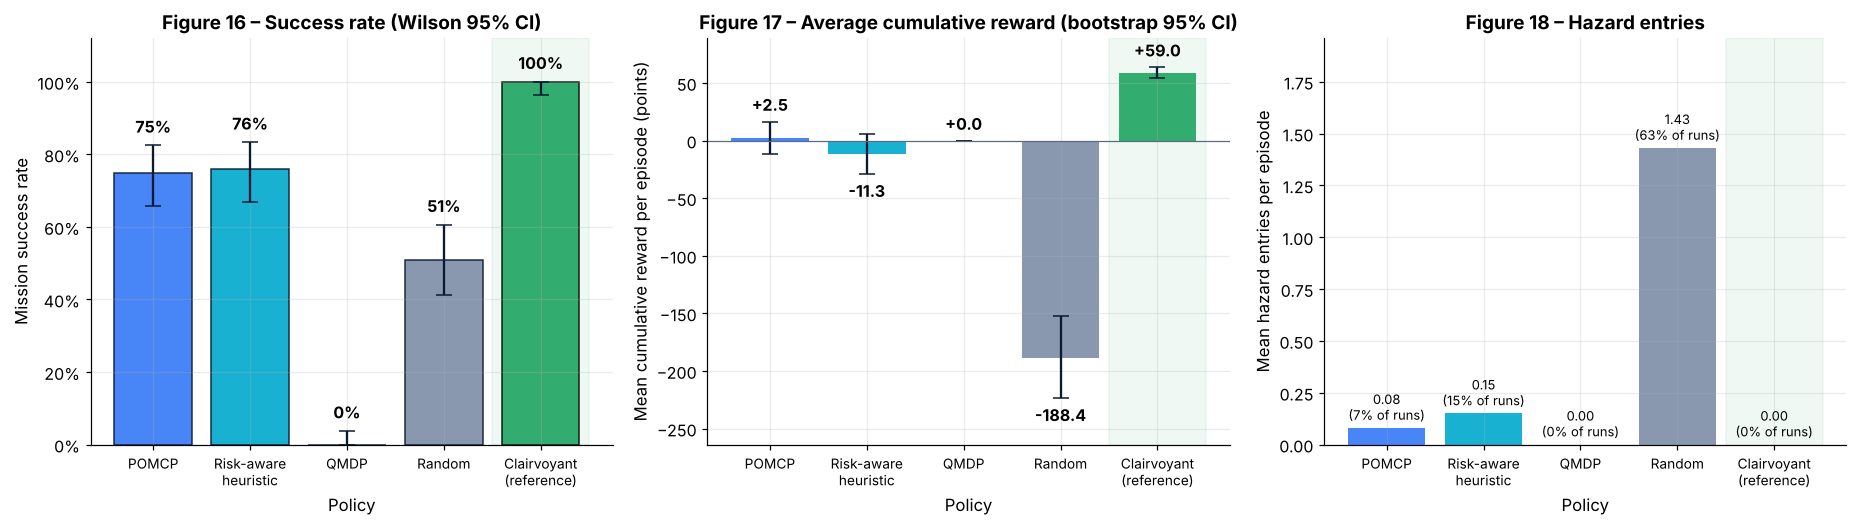

In [21]:
order = [s.label for s in SPECS]
S = summary.set_index("Policy").loc[order]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.9))
x = np.arange(len(order)); colors = [POLICY_COLORS[p] for p in order]
short = ["POMCP", "Risk-aware\nheuristic", "QMDP", "Random", "Clairvoyant\n(reference)"]
# success
ax = axes[0]
ax.bar(x, S["Success rate"], color=colors, alpha=0.9, edgecolor=[PAL["navy"]]*4 + ["none"])
ax.errorbar(x, S["Success rate"], yerr=[S["Success rate"] - S["success_lo"], S["success_hi"] - S["Success rate"]], fmt="none", ecolor=PAL["navy"], capsize=5)
for i, (v, h_) in enumerate(zip(S["Success rate"], S["success_hi"])): ax.text(i, h_ + 0.025, f"{v:.0%}", ha="center", va="bottom", fontweight="bold")
ax.set_ylim(0, 1.12); ax.set_ylabel("Mission success rate"); ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Figure 16 – Success rate (Wilson 95% CI)")
# reward
ax = axes[1]
ax.bar(x, S["Mean reward"], color=colors, alpha=0.9)
ax.errorbar(x, S["Mean reward"], yerr=[S["Mean reward"] - S["reward_lo"], S["reward_hi"] - S["Mean reward"]], fmt="none", ecolor=PAL["navy"], capsize=5)
for i, (v, l_, h_) in enumerate(zip(S["Mean reward"], S["reward_lo"], S["reward_hi"])):
    ax.text(i, h_ + 6 if v >= 0 else l_ - 6, f"{v:+.1f}", ha="center", va="bottom" if v >= 0 else "top", fontweight="bold")
ax.axhline(0, color="#5B6B82", lw=0.8); ax.set_ylabel("Mean cumulative reward per episode (points)")
ax.set_ylim(min(S["reward_lo"].min() - 40, -40), max(S["reward_hi"].max() + 25, 30))
ax.set_title("Figure 17 – Average cumulative reward (bootstrap 95% CI)")
# hazards
ax = axes[2]
ax.bar(x, S["Mean hazard entries"], color=colors, alpha=0.9)
for i, (v, r) in enumerate(zip(S["Mean hazard entries"], S["Hazard-entry rate"])): ax.text(i, v + 0.04, f"{v:.2f}\n({r:.0%} of runs)", ha="center", fontsize=8.5)
ax.set_ylabel("Mean hazard entries per episode"); ax.set_ylim(0, S["Mean hazard entries"].max() * 1.3 + 0.1)
ax.set_title("Figure 18 – Hazard entries")
for ax in axes:
    ax.set_xticks(x, short, fontsize=9); ax.set_xlabel("Policy")
    ax.axvspan(3.5, 4.5, color=PAL["green"], alpha=0.07)
plt.tight_layout(); plt.show()

**Paired, seed-matched comparisons.** Episode *i* uses the same survivor cell and the same pre-drawn movement and sensor random numbers for every policy. The differences are computed per episode and then averaged; the interval is a percentile bootstrap (5,000 resamples) of those 100 paired differences.

Comparison,Metric,Mean paired difference,Bootstrap 95% CI
POMCP − risk-aware heuristic,Cumulative reward,+13.80,"[-3.0, +31.3]"
POMCP − risk-aware heuristic,Discounted return,+7.19,"[-1.8, +16.1]"
POMCP − QMDP,Cumulative reward,+2.50,"[-11.7, +15.9]"
POMCP − QMDP,Discounted return,+0.40,"[-8.6, +9.5]"


Discordant rescue outcomes (the counts a McNemar test would use; no p-value is reported):
  POMCP vs heuristic: POMCP-only 12, heuristic-only 13
  POMCP vs QMDP     : POMCP-only 75, QMDP-only 0


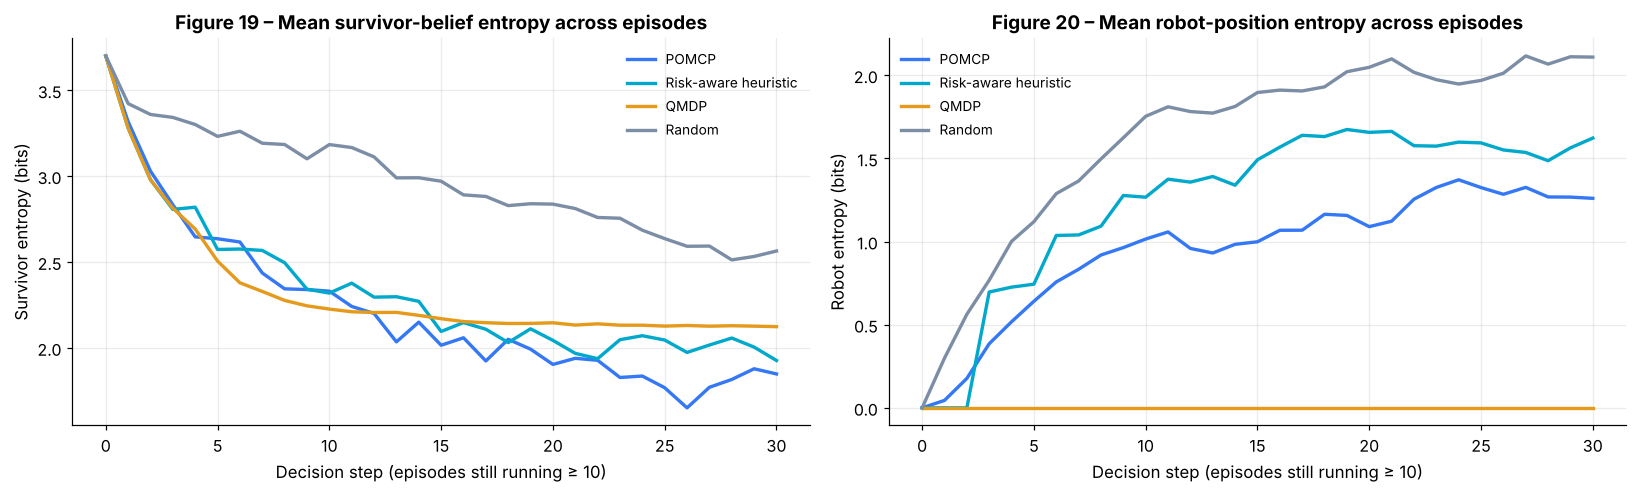

In [22]:
# Paired comparison POMCP vs. heuristic using common random numbers
pv = eval_df.pivot(index="episode", columns="policy")
diff_r = pv["total_reward"]["POMCP"] - pv["total_reward"]["Risk-aware heuristic"]
diff_d = pv["discounted_return"]["POMCP"] - pv["discounted_return"]["Risk-aware heuristic"]
lo_r, hi_r = bootstrap_ci(diff_r, seed=1); lo_d, hi_d = bootstrap_ci(diff_d, seed=2)
s_p, s_h = pv["success"]["POMCP"], pv["success"]["Risk-aware heuristic"]
only_p, only_h = int((s_p & ~s_h).sum()), int((~s_p & s_h).sum())
# POMCP − QMDP on the same seeds (no new simulations: the same Table A episodes)
diff_rq = pv["total_reward"]["POMCP"] - pv["total_reward"]["QMDP"]
diff_dq = pv["discounted_return"]["POMCP"] - pv["discounted_return"]["QMDP"]
lo_rq, hi_rq = bootstrap_ci(diff_rq, seed=3); lo_dq, hi_dq = bootstrap_ci(diff_dq, seed=4)
s_q = pv["success"]["QMDP"]
only_pq, only_q = int((s_p & ~s_q).sum()), int((~s_p & s_q).sum())
paired = pd.DataFrame([
    {"Comparison": "POMCP − risk-aware heuristic", "Metric": "Cumulative reward", "Mean paired difference": diff_r.mean(), "Bootstrap 95% CI": f"[{lo_r:+.1f}, {hi_r:+.1f}]"},
    {"Comparison": "POMCP − risk-aware heuristic", "Metric": "Discounted return", "Mean paired difference": diff_d.mean(), "Bootstrap 95% CI": f"[{lo_d:+.1f}, {hi_d:+.1f}]"},
    {"Comparison": "POMCP − QMDP", "Metric": "Cumulative reward", "Mean paired difference": diff_rq.mean(), "Bootstrap 95% CI": f"[{lo_rq:+.1f}, {hi_rq:+.1f}]"},
    {"Comparison": "POMCP − QMDP", "Metric": "Discounted return", "Mean paired difference": diff_dq.mean(), "Bootstrap 95% CI": f"[{lo_dq:+.1f}, {hi_dq:+.1f}]"},
])
display(Markdown("**Paired, seed-matched comparisons.** Episode *i* uses the same survivor cell and the same pre-drawn movement and sensor random numbers for every policy. "
                 "The differences are computed per episode and then averaged; the interval is a percentile bootstrap (5,000 resamples) of those 100 paired differences."))
display(paired.style.format({"Mean paired difference": "{:+.2f}"}).hide(axis="index"))
print(f"Discordant rescue outcomes (the counts a McNemar test would use; no p-value is reported):")
print(f"  POMCP vs heuristic: POMCP-only {only_p}, heuristic-only {only_h}")
print(f"  POMCP vs QMDP     : POMCP-only {only_pq}, QMDP-only {only_q}")
pd.concat([paired.assign(**{"Discordant (A-only / B-only)": [f"{only_p} / {only_h}"] * 2 + [f"{only_pq} / {only_q}"] * 2})]).to_csv(
    "results/paired_comparisons.csv", index=False)

# survivor entropy traces by policy
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for pol in ["POMCP", "Risk-aware heuristic", "QMDP", "Random"]:
    tr = eval_df.loc[eval_df.policy == pol, "trace_survivor_entropy"]
    mat = np.full((len(tr), 31), np.nan)
    for i, t in enumerate(tr): mat[i, :len(t)] = t
    m = np.nanmean(mat, axis=0); n_alive = (~np.isnan(mat)).sum(0)
    keep = n_alive >= 10
    axes[0].plot(np.arange(31)[keep], m[keep], lw=2.2, color=POLICY_COLORS[pol], label=pol)
    trr = eval_df.loc[eval_df.policy == pol, "trace_robot_entropy"]
    mat = np.full((len(trr), 31), np.nan)
    for i, t in enumerate(trr): mat[i, :len(t)] = t
    axes[1].plot(np.arange(31)[keep], np.nanmean(mat, axis=0)[keep], lw=2.2, color=POLICY_COLORS[pol], label=pol)
axes[0].set_title("Figure 19 – Mean survivor-belief entropy across episodes"); axes[0].set_ylabel("Survivor entropy (bits)")
axes[1].set_title("Figure 20 – Mean robot-position entropy across episodes"); axes[1].set_ylabel("Robot entropy (bits)")
for ax in axes:
    ax.set_xlabel("Decision step (episodes still running ≥ 10)"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

In [23]:
P = S.loc["POMCP"]; H = S.loc["Risk-aware heuristic"]; Qm = S.loc["QMDP"]; Rn = S.loc["Random"]; C = S.loc["Clairvoyant (reference)"]
F = fixed_summary.set_index("Policy")
best_succ = S.drop(index="Clairvoyant (reference)")["Success rate"].idxmax()
best_rew = S.drop(index="Clairvoyant (reference)")["Mean reward"].idxmax()
scan_share = Qm['Mean scans'] / max(Qm['Mean steps'], 1e-9)
if scan_share > 0.9:
    qmdp_txt = (f"QMDP scanned on {Qm['Mean scans']:.1f} of {Qm['Mean steps']:.1f} steps on average and rescued {Qm['Success rate']:.0%}. "
                "Its Q-values assume all uncertainty vanishes after one step. Averaging the MDP move values over hypotheses that want "
                "different directions makes Scan (MDP value γ·V, and *free* in the assignment model) look best. Because QMDP places no value "
                "on information, it never benefits from the scans it keeps choosing. Section 13b tests whether the free scan is what causes "
                "this stall.")
else:
    qmdp_txt = (f"QMDP scanned on {Qm['Mean scans']:.1f} of {Qm['Mean steps']:.1f} steps and rescued {Qm['Success rate']:.0%} "
                f"with mean reward {Qm['Mean reward']:+.1f}. It values no information, so any scan it takes is incidental.")
display(Markdown(f'''
**Interpretation (generated from Table A).**

* **Mission completion.** Among deployable policies, **{best_succ}** has the highest success rate. POMCP rescued the survivor in **{P['Success rate']:.0%}** of episodes (95% CI {P['Success 95% CI']}), the heuristic in **{H['Success rate']:.0%}** ({H['Success 95% CI']}), QMDP in **{Qm['Success rate']:.0%}** and Random in **{Rn['Success rate']:.0%}**. With perfect information (clairvoyant) the rate is {C['Success rate']:.0%}.
* **Accumulated reward.** Mean cumulative reward: POMCP **{P['Mean reward']:+.1f}** {P['Reward 95% CI']}, heuristic **{H['Mean reward']:+.1f}** {H['Reward 95% CI']}, QMDP {Qm['Mean reward']:+.1f}, Random **{Rn['Mean reward']:+.1f}**, clairvoyant {C['Mean reward']:+.1f}. The best deployable policy on this metric is **{best_rew}**{" (by never moving: a failed mission costs nothing and scans are free, so 'do nothing' scores 0)" if best_rew == "QMDP" else ""}. The paired (seed-matched) POMCP − heuristic difference is {diff_r.mean():+.1f} points (95% CI [{lo_r:+.1f}, {hi_r:+.1f}]); {'this interval excludes zero' if (lo_r > 0 or hi_r < 0) else 'this interval includes zero, so the two policies are not distinguishable on cumulative reward at this sample size'}. On discounted return, the planner's own objective, the paired difference is {diff_d.mean():+.1f} (95% CI [{lo_d:+.1f}, {hi_d:+.1f}]){', which excludes zero' if (lo_d > 0 or hi_d < 0) else ', which includes zero'}. Rescues: POMCP succeeded where the heuristic failed in {only_p} episodes, and the reverse in {only_h}.
* **The value of information.** The gap between the clairvoyant reference ({C['Mean reward']:+.1f}) and the best deployable policy is the cost of partial observability. No planner can close it fully, because the survivor's location must be *discovered*.
* **Hazard avoidance.** POMCP entered a hazard in {P['Hazard-entry rate']:.0%} of episodes and the heuristic in {H['Hazard-entry rate']:.0%}, against {Rn['Hazard-entry rate']:.0%} for Random. Belief-based policies can still enter hazards for two reasons. Unobserved position drift means a move intended to pass *beside* a hazard can enter it. And a short-cut through a hazard can be worth −50 when the alternative is a long detour under uncertainty.
* **Navigation efficiency.** Successful POMCP missions took {P['Steps to rescue (successes)']:.1f} steps on average, against {H['Steps to rescue (successes)']:.1f} for the heuristic and {C['Steps to rescue (successes)']:.1f} for the clairvoyant optimum.
* **QMDP.** {qmdp_txt}
* **Fixed (4,4) scenario (Table B).** POMCP {F.loc['POMCP','Success rate']:.0%} success / {F.loc['POMCP','Mean reward']:+.1f} points, heuristic {F.loc['Risk-aware heuristic','Success rate']:.0%} / {F.loc['Risk-aware heuristic','Mean reward']:+.1f}. Even the clairvoyant optimum earns only {F.loc['Clairvoyant (reference)','Mean reward']:+.1f} here: a survivor in the far corner is barely worth the travel under the slide's reward values.
'''))


**Interpretation (generated from Table A).**

* **Mission completion.** Among deployable policies, **Risk-aware heuristic** has the highest success rate. POMCP rescued the survivor in **75%** of episodes (95% CI [0.66, 0.82]), the heuristic in **76%** ([0.67, 0.83]), QMDP in **0%** and Random in **51%**. With perfect information (clairvoyant) the rate is 100%.
* **Accumulated reward.** Mean cumulative reward: POMCP **+2.5** [-11.3, 16.5], heuristic **-11.3** [-29.4, 6.0], QMDP +0.0, Random **-188.4**, clairvoyant +59.0. The best deployable policy on this metric is **POMCP**. The paired (seed-matched) POMCP − heuristic difference is +13.8 points (95% CI [-3.0, +31.3]); this interval includes zero, so the two policies are not distinguishable on cumulative reward at this sample size. On discounted return, the planner's own objective, the paired difference is +7.2 (95% CI [-1.8, +16.1]), which includes zero. Rescues: POMCP succeeded where the heuristic failed in 12 episodes, and the reverse in 13.
* **The value of information.** The gap between the clairvoyant reference (+59.0) and the best deployable policy is the cost of partial observability. No planner can close it fully, because the survivor's location must be *discovered*.
* **Hazard avoidance.** POMCP entered a hazard in 7% of episodes and the heuristic in 15%, against 63% for Random. Belief-based policies can still enter hazards for two reasons. Unobserved position drift means a move intended to pass *beside* a hazard can enter it. And a short-cut through a hazard can be worth −50 when the alternative is a long detour under uncertainty.
* **Navigation efficiency.** Successful POMCP missions took 13.7 steps on average, against 14.4 for the heuristic and 4.1 for the clairvoyant optimum.
* **QMDP.** QMDP scanned on 30.0 of 30.0 steps on average and rescued 0%. Its Q-values assume all uncertainty vanishes after one step. Averaging the MDP move values over hypotheses that want different directions makes Scan (MDP value γ·V, and *free* in the assignment model) look best. Because QMDP places no value on information, it never benefits from the scans it keeps choosing. Section 13b tests whether the free scan is what causes this stall.
* **Fixed (4,4) scenario (Table B).** POMCP 76% success / -35.0 points, heuristic 72% / -50.0. Even the clairvoyant optimum earns only +24.6 here: a survivor in the far corner is barely worth the travel under the slide's reward values.


### 13b. Optional costed-scan experiment (reward-structure check)

The assignment model makes **Scan free**, because the slide specifies no scan penalty, and that remains the main experiment above. A free scan has a side effect: "scan forever" is worth exactly 0 points, so a policy that never commits loses nothing. To show how the *reward structure* shapes behaviour, every policy (QMDP included) is re-run with a **scan cost of 2 points**, one-fifth of a move. The cost is small enough that scanning stays worthwhile and large enough that waiting is no longer free. All other settings, seeds and survivor draws are identical to Table A (50 episodes per policy). This is an extension for interpretation, not a change to the assignment model. It reports per-policy estimates only; no paired significance test is performed for it.

Costed-scan evaluation: 250 episodes in 39s


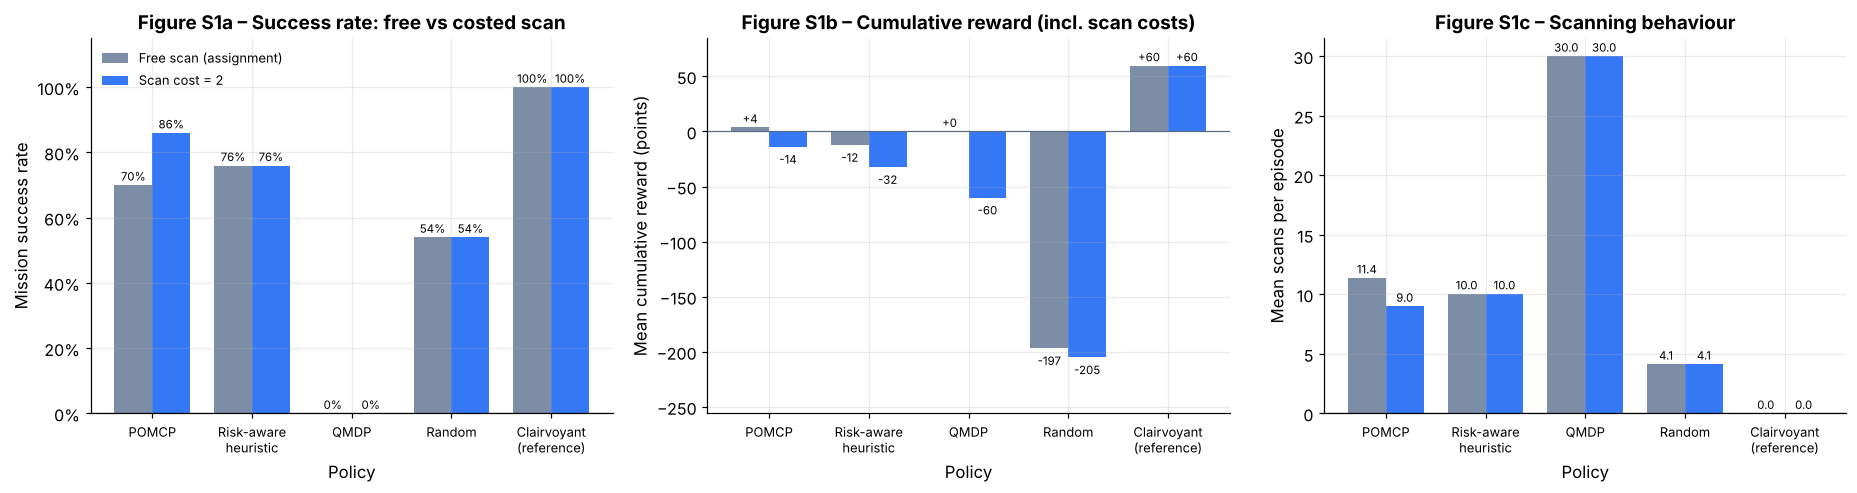


*Interpretation (generated).*

* **QMDP:** 30.0 → 30.0 scans per episode, success 0% → 0%, reward +0.0 → -60.0. Even with a cost, QMDP keeps scanning: averaging MDP move values over disagreeing hypotheses still makes waiting look best. Its weakness is structural (no value of information), not only a consequence of the free scan.
* **POMCP:** 11.4 → 9.0 scans, success 70% → 86%, reward +3.6 → -13.8.
* **Risk-aware heuristic:** 10.0 → 10.0 scans, success 76% → 76%. Its scan rule ignores costs by construction, so any change comes only from the cost added to its reward.

The reward function is part of the problem specification, not a detail: identical planners produce different behaviour when the price of information changes.


In [24]:
cfg_cost = cfg.with_(scan_cost=2.0)
t0 = time.time()
cost_df = evaluate_policies(cfg_cost, SPECS, n_episodes=50, base_seed=2026, survivor_mode="random", n_jobs=N_JOBS)
cost_summary = summarise_evaluation(cost_df)
cost_df.to_json("results/evaluation_costed_scan_episodes.json", orient="records")
cost_summary.to_csv("results/evaluation_costed_scan_summary.csv", index=False)
base50 = summarise_evaluation(eval_df[eval_df.episode < 50])   # same 50 seeds under the free-scan model
print(f"Costed-scan evaluation: {len(cost_df)} episodes in {time.time()-t0:.0f}s")
cmp_cols = ["Success rate", "Mean reward", "Mean discounted return", "Mean scans", "Mean steps", "Hazard-entry rate"]
both = pd.concat({"Free scan (assignment)": base50.set_index("Policy")[cmp_cols],
                  "Scan cost = 2": cost_summary.set_index("Policy")[cmp_cols]}, axis=1)
display(both.style.format("{:.2f}"))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
pols = [s_.label for s_ in SPECS]; x = np.arange(len(pols)); w = 0.38
short = ["POMCP", "Risk-aware\nheuristic", "QMDP", "Random", "Clairvoyant\n(reference)"]
for ax, metric, ylab, f in [(axes[0], "Success rate", "Mission success rate", "{:.0%}"),
                            (axes[1], "Mean reward", "Mean cumulative reward (points)", "{:+.0f}"),
                            (axes[2], "Mean scans", "Mean scans per episode", "{:.1f}")]:
    v0 = base50.set_index("Policy").loc[pols, metric].values; v1 = cost_summary.set_index("Policy").loc[pols, metric].values
    b0_ = ax.bar(x - w/2, v0, w, color=PAL["grey"], label="Free scan (assignment)")
    b1_ = ax.bar(x + w/2, v1, w, color=PAL["blue"], label="Scan cost = 2")
    for bars_, vals_ in [(b0_, v0), (b1_, v1)]:
        for bb_, v in zip(bars_, vals_):
            ax.annotate(f.format(v), (bb_.get_x() + bb_.get_width()/2, v), textcoords="offset points",
                        xytext=(0, 3 if v >= 0 else -11), ha="center", fontsize=7.5)
    ax.set_xticks(x, short, fontsize=8.5); ax.set_xlabel("Policy"); ax.set_ylabel(ylab); ax.axhline(0, color="#5B6B82", lw=0.8)
    if metric == "Success rate":
        ax.set_ylim(0, 1.15); ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    if metric == "Mean reward":
        lo_ = min(v0.min(), v1.min()); ax.set_ylim(lo_ * 1.2 - 10 if lo_ < 0 else 0, max(v0.max(), v1.max()) * 1.25 + 10)
axes[0].set_title("Figure S1a – Success rate: free vs costed scan"); axes[1].set_title("Figure S1b – Cumulative reward (incl. scan costs)")
axes[2].set_title("Figure S1c – Scanning behaviour")
axes[0].legend(fontsize=8.5, loc="upper left")
plt.tight_layout(); plt.show()

Qf, Qc = base50.set_index("Policy").loc["QMDP"], cost_summary.set_index("Policy").loc["QMDP"]
Pf, Pc = base50.set_index("Policy").loc["POMCP"], cost_summary.set_index("Policy").loc["POMCP"]
Hf, Hc = base50.set_index("Policy").loc["Risk-aware heuristic"], cost_summary.set_index("Policy").loc["Risk-aware heuristic"]
display(Markdown(f'''
*Interpretation (generated).*

* **QMDP:** {Qf['Mean scans']:.1f} → {Qc['Mean scans']:.1f} scans per episode, success {Qf['Success rate']:.0%} → {Qc['Success rate']:.0%}, reward {Qf['Mean reward']:+.1f} → {Qc['Mean reward']:+.1f}. {"Once waiting is no longer free, QMDP starts moving: its stall under the assignment model was driven by the free scan, not only by its information-blindness." if Qc['Mean scans'] < 0.8 * Qf['Mean scans'] else "Even with a cost, QMDP keeps scanning: averaging MDP move values over disagreeing hypotheses still makes waiting look best. Its weakness is structural (no value of information), not only a consequence of the free scan."}
* **POMCP:** {Pf['Mean scans']:.1f} → {Pc['Mean scans']:.1f} scans, success {Pf['Success rate']:.0%} → {Pc['Success rate']:.0%}, reward {Pf['Mean reward']:+.1f} → {Pc['Mean reward']:+.1f}.
* **Risk-aware heuristic:** {Hf['Mean scans']:.1f} → {Hc['Mean scans']:.1f} scans, success {Hf['Success rate']:.0%} → {Hc['Success rate']:.0%}. Its scan rule ignores costs by construction, so any change comes only from the cost added to its reward.

The reward function is part of the problem specification, not a detail: identical planners produce different behaviour when the price of information changes.
'''))

## 14. Sensitivity analysis

**Design.** Each sweep varies one factor at a time, keeping everything else at the defaults. Every point uses 40 episodes, the same survivor draws and random numbers (common random numbers across sweep points), and the survivor sampled from the prior. One-factor sweeps are *local* checks: they do not test interactions between factors. The intervals show the uncertainty at each point.

Factors:
1. movement success probability $p$
2. sensor noise level (0 = noiseless, 1 = baseline table, 2 = uninformative)
3. POMCP simulation budget
4. POMCP search depth
5. optional scan-energy cost
6. UCB exploration constant c. These seeds (base seed 77) are the **development seeds** used to select the default c = 150 by the rule "highest mean discounted return" (Section 11). The rows are reproduced here, and the cell after the figures re-checks the rule.
7. rescue reward (a reward-design check)

Each factor gets its own figure with three panels: success rate (Wilson 95% CI), mean cumulative reward and mean discounted return (bootstrap 95% CI). Discounted return is shown because it is the quantity POMCP actually maximises.

In [25]:
SENS_N = 40
POL2 = [rb.DEFAULT_POMCP, PolicySpec.of("heuristic")]
sweeps = [("p_success", [0.6, 0.7, 0.8, 0.9, 1.0], POL2),
          ("sensor_noise", [0.0, 0.5, 1.0, 1.5, 2.0], POL2),
          ("pomcp.n_simulations", [50, 200, 800, 2000], [rb.DEFAULT_POMCP]),
          ("pomcp.horizon", [2, 5, 10, 15], [rb.DEFAULT_POMCP]),
          ("scan_cost", [0.0, 1.0, 3.0, 5.0], POL2),
          ("pomcp.exploration", [5.0, 20.0, 50.0, 100.0, 150.0, 300.0], [rb.DEFAULT_POMCP]),
          ("rescue_reward", [100.0, 200.0, 400.0], POL2)]
frames = []
t0 = time.time()
for param, values, pols in sweeps:
    t1 = time.time()
    frames.append(sensitivity_sweep(cfg, param, values, pols, n_episodes=SENS_N, base_seed=77, n_jobs=N_JOBS))
    print(f"  {param:22s} done in {time.time()-t1:5.0f}s")
sens = pd.concat(frames, ignore_index=True)
sens.to_csv("results/sensitivity_results.csv", index=False)
print(f"Sensitivity analysis: {len(sens)} configuration×policy cells in {time.time()-t0:.0f}s")
display(sens[["parameter", "value", "Policy", "Success rate", "Mean reward", "Mean discounted return", "Mean steps", "Mean scans", "Mean hazard entries"]]
        .style.format({"Success rate": "{:.0%}", "Mean reward": "{:+.1f}", "Mean discounted return": "{:+.1f}", "Mean steps": "{:.1f}",
                       "Mean scans": "{:.1f}", "Mean hazard entries": "{:.2f}"}).hide(axis="index"))

  p_success              done in   150s


  sensor_noise           done in   151s


  pomcp.n_simulations    done in   124s


  pomcp.horizon          done in   112s


  scan_cost              done in   112s


  pomcp.exploration      done in   183s


  rescue_reward          done in    84s
Sensitivity analysis: 48 configuration×policy cells in 915s


parameter,value,Policy,Success rate,Mean reward,Mean discounted return,Mean steps,Mean scans,Mean hazard entries
p_success,0.600000,POMCP,40%,-14.2,-5.5,22.2,17.0,0.05
p_success,0.600000,Risk-aware heuristic,57%,-48.0,-27.9,22.4,13.2,0.28
p_success,0.700000,POMCP,65%,-10.8,-6.8,19.5,12.7,0.15
p_success,0.700000,Risk-aware heuristic,72%,-26.0,-17.7,20.2,11.5,0.23
p_success,0.800000,POMCP,88%,+21.8,+6.8,15.5,9.3,0.07
p_success,0.800000,Risk-aware heuristic,80%,-11.5,-7.1,17.4,9.7,0.30
p_success,0.900000,POMCP,90%,+27.5,+11.0,15.0,8.9,0.03
p_success,0.900000,Risk-aware heuristic,90%,+16.5,+8.0,14.2,8.0,0.23
p_success,1.000000,POMCP,92%,+52.5,+35.2,11.5,7.6,0.03
p_success,1.000000,Risk-aware heuristic,100%,+53.0,+30.3,10.6,5.9,0.00


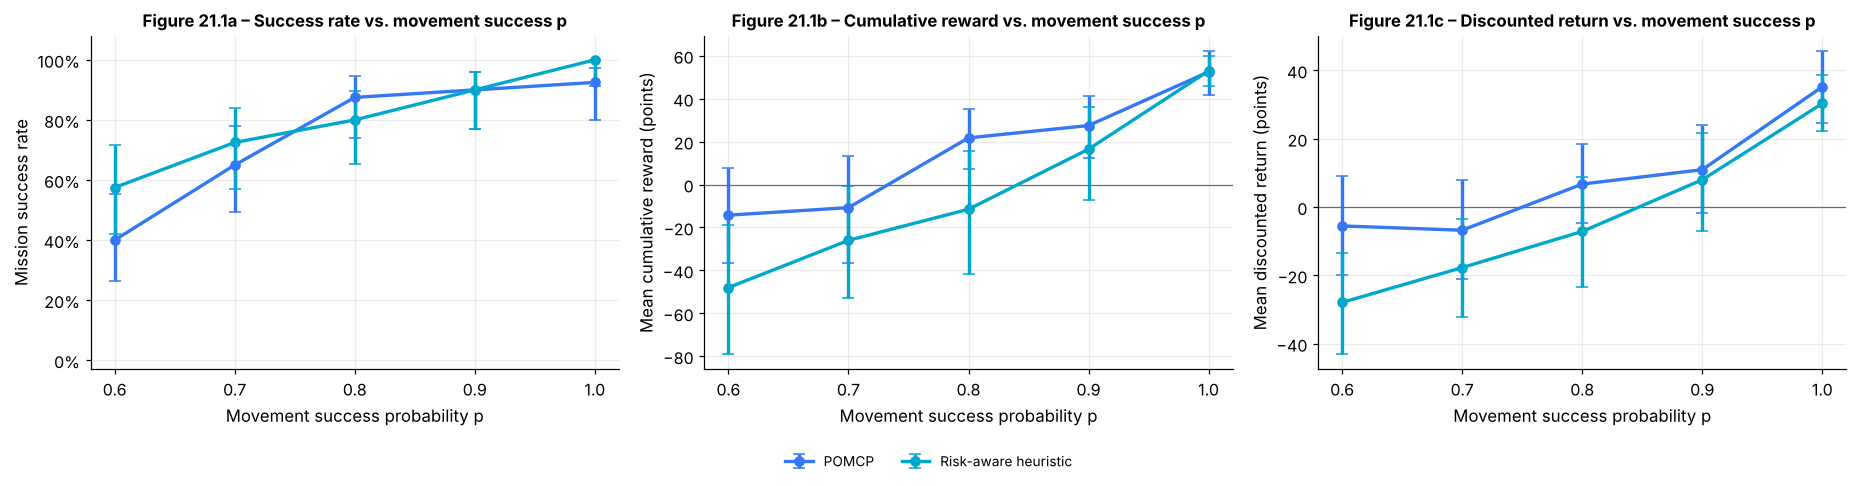

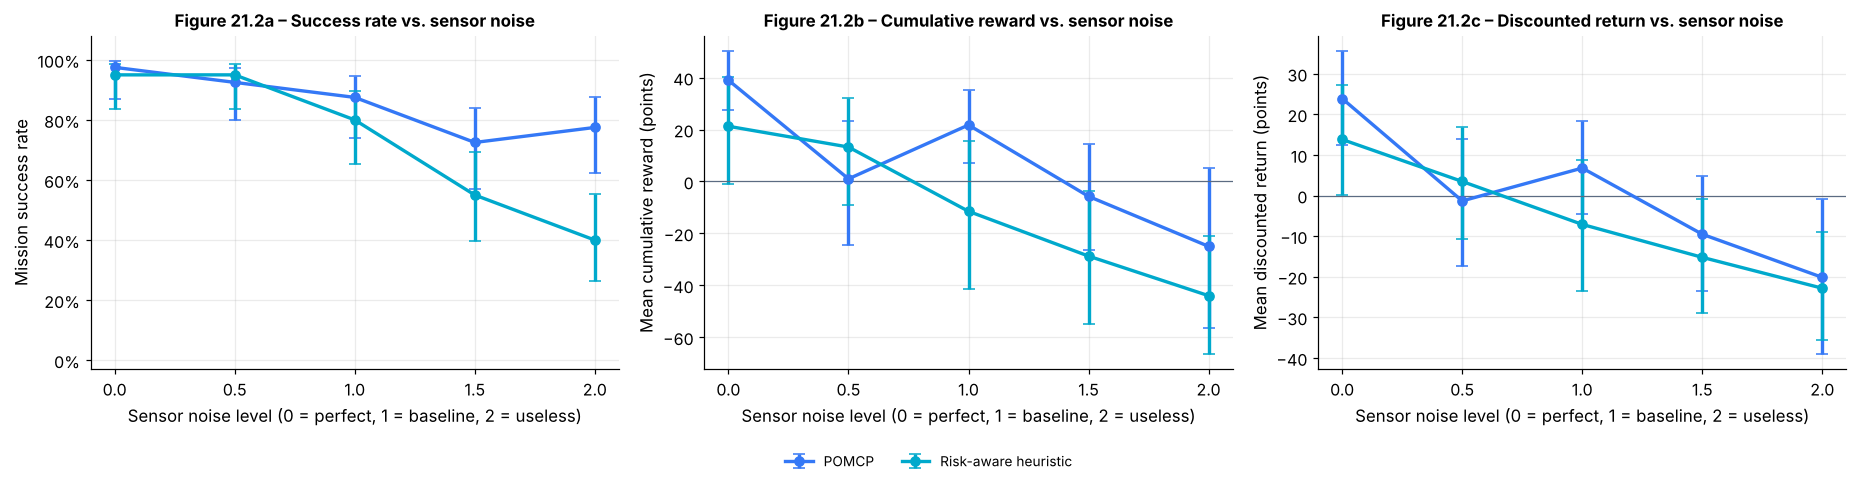

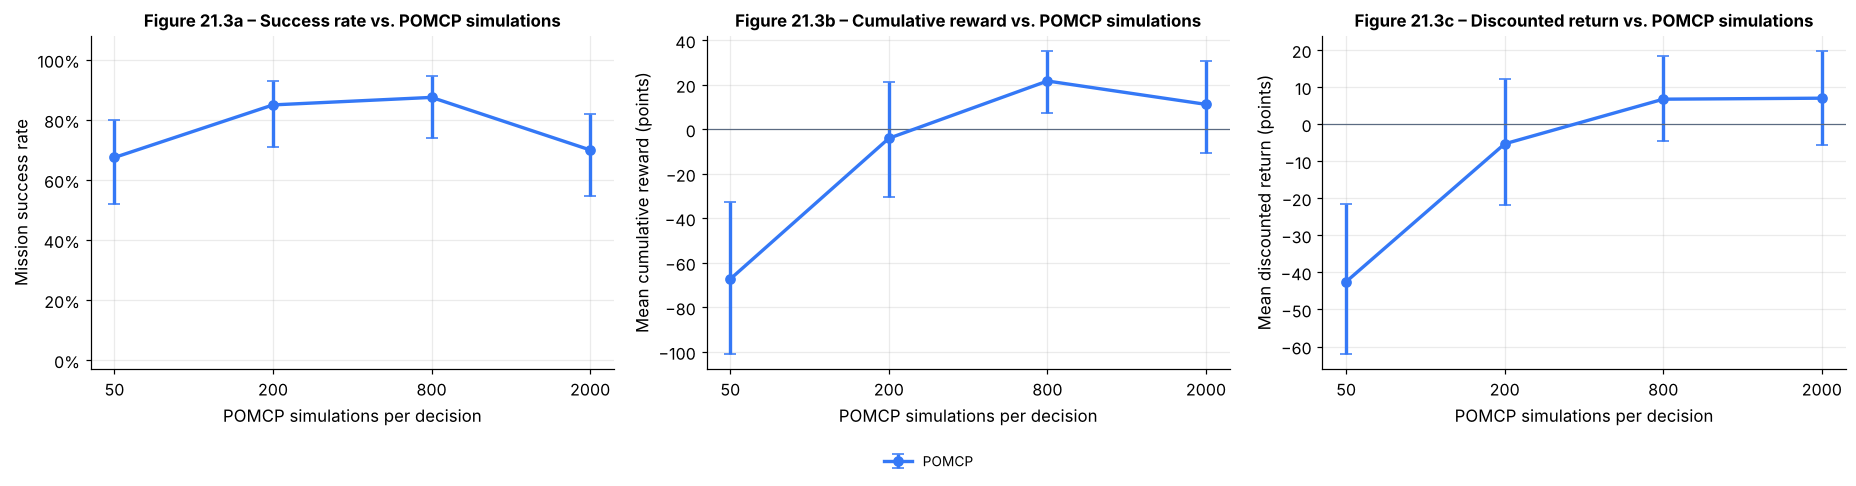

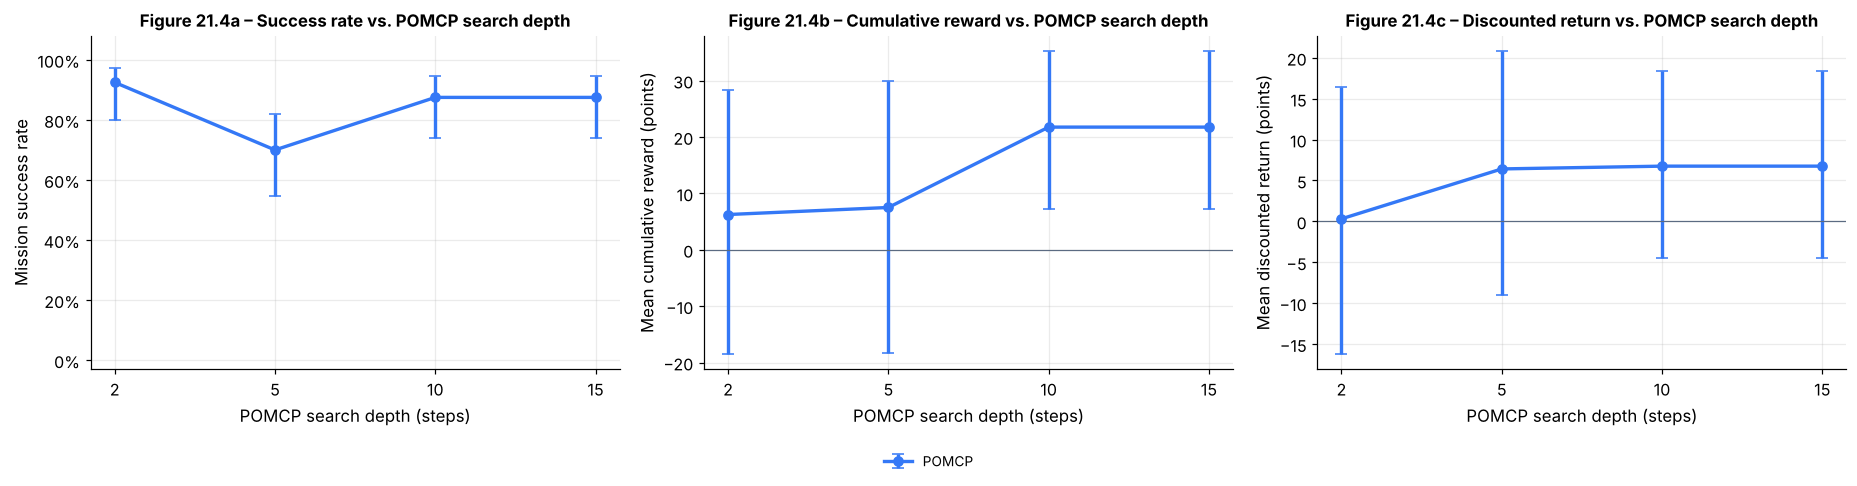

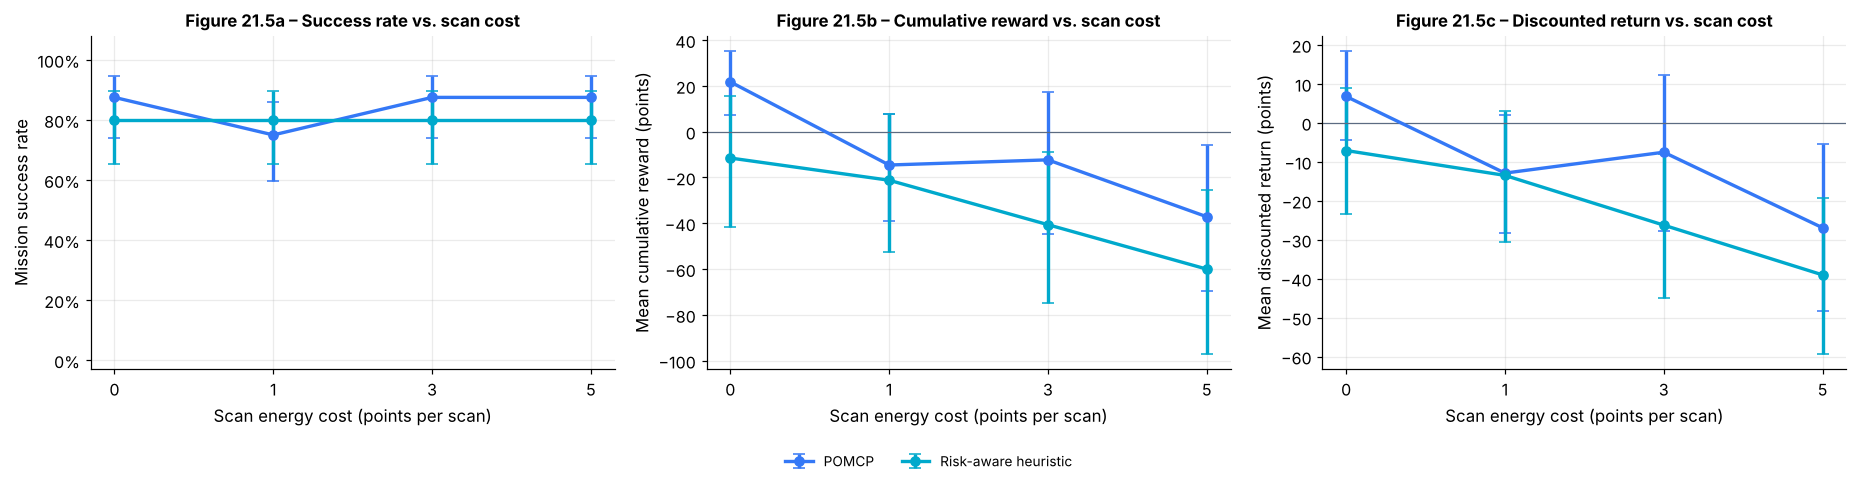

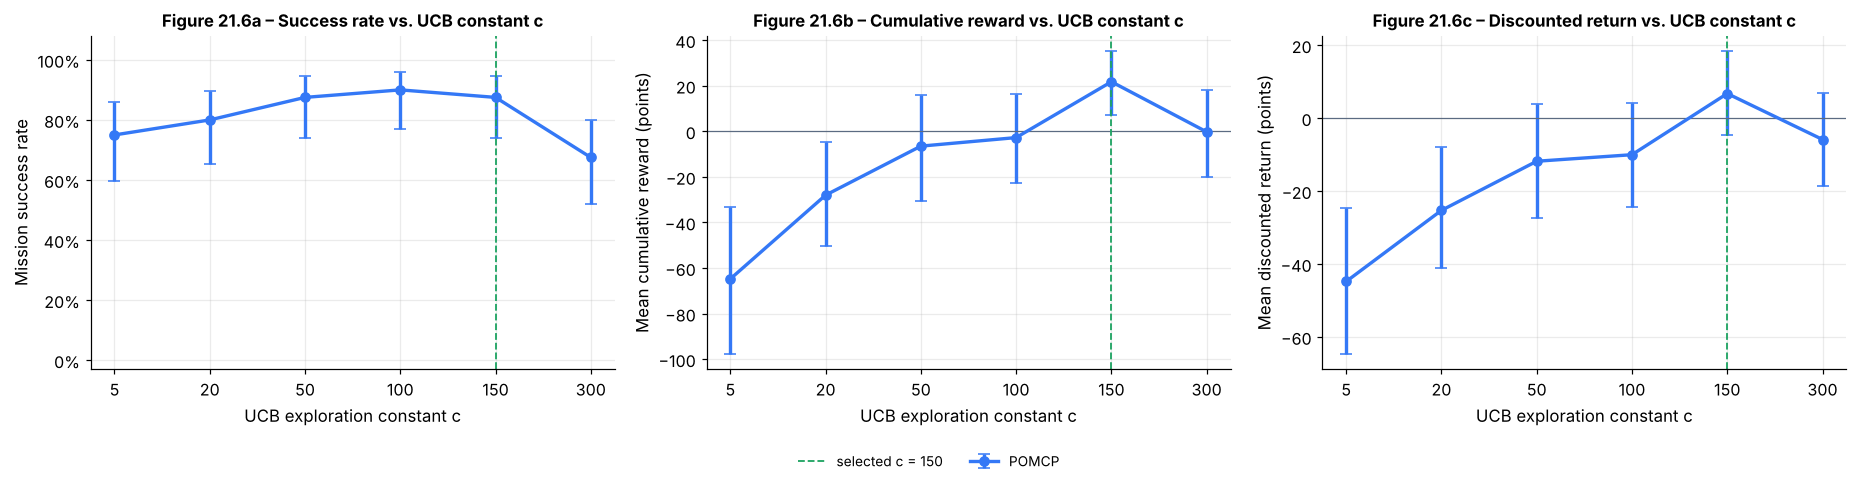

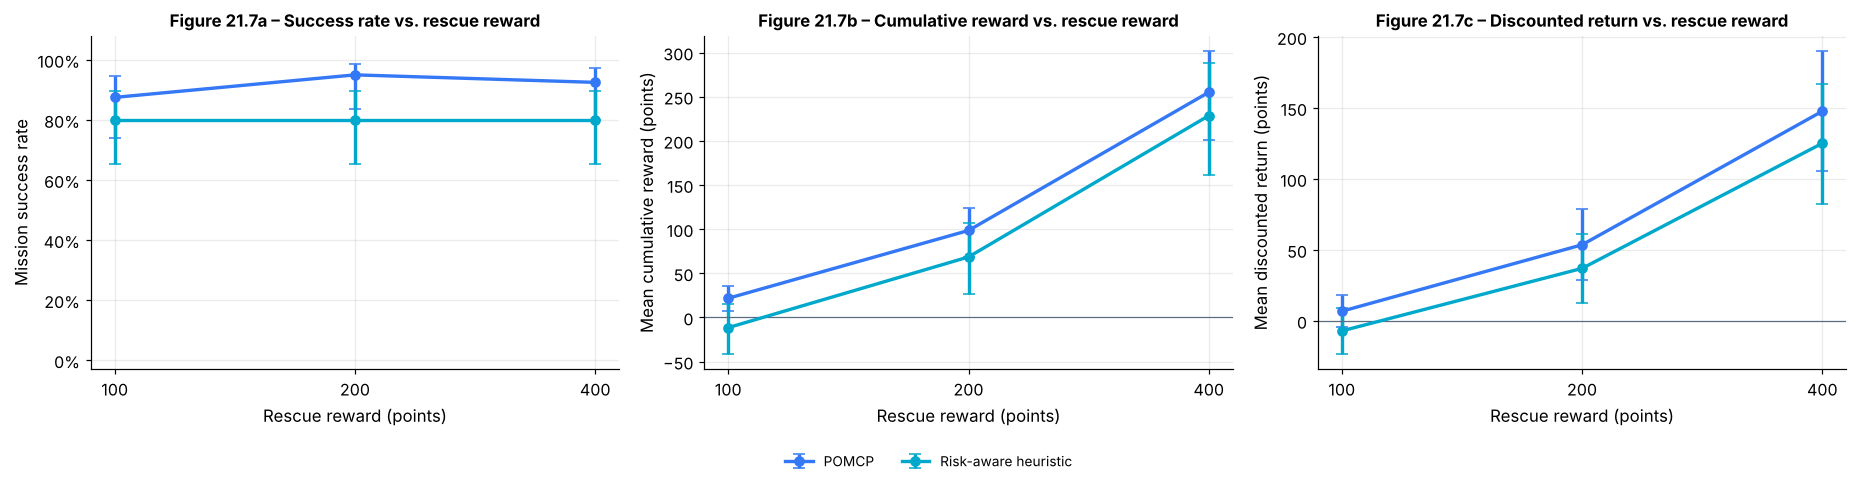

In [26]:
titles = {"p_success": ("Movement success probability p", "{:.1f}"), "sensor_noise": ("Sensor noise level (0 = perfect, 1 = baseline, 2 = useless)", "{:.1f}"),
          "pomcp.n_simulations": ("POMCP simulations per decision", "{:.0f}"), "pomcp.horizon": ("POMCP search depth (steps)", "{:.0f}"),
          "scan_cost": ("Scan energy cost (points per scan)", "{:.0f}"), "pomcp.exploration": ("UCB exploration constant c", "{:.0f}"),
          "rescue_reward": ("Rescue reward (points)", "{:.0f}")}
panels = [("Success rate", "success_lo", "success_hi", "Mission success rate"),
          ("Mean reward", "reward_lo", "reward_hi", "Mean cumulative reward (points)"),
          ("Mean discounted return", "disc_lo", "disc_hi", "Mean discounted return (points)")]
for row, (param, (xlabel, f)) in enumerate(titles.items()):
    d_ = sens[sens.parameter == param]
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
    short_x = {"p_success": "movement success p", "sensor_noise": "sensor noise", "pomcp.n_simulations": "POMCP simulations",
               "pomcp.horizon": "POMCP search depth", "scan_cost": "scan cost", "pomcp.exploration": "UCB constant c",
               "rescue_reward": "rescue reward"}[param]
    for pol, g in d_.groupby("Policy", sort=False):
        xs = np.arange(len(g)); col = POLICY_COLORS[pol]
        for ax, (m, lo_c, hi_c, ylab) in zip(axes, panels):
            ax.errorbar(xs, g[m], yerr=[np.clip(g[m] - g[lo_c], 0, None), np.clip(g[hi_c] - g[m], 0, None)],
                        fmt="-o", color=col, capsize=4, lw=2.2, ms=6, label=pol)
            ax.set_xticks(xs, [f.format(v) for v in g["value"]])
    for k, (ax, (m, lo_c, hi_c, ylab)) in enumerate(zip(axes, panels)):
        ax.set_xlabel(xlabel); ax.set_ylabel(ylab)
        ax.set_title(f"Figure 21.{row+1}{'abc'[k]} – {['Success rate', 'Cumulative reward', 'Discounted return'][k]} vs. {short_x}",
                     fontsize=11)
        if m == "Success rate":
            ax.set_ylim(-0.03, 1.08); ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
        else:
            ax.axhline(0, color="#5B6B82", lw=0.8)
    if param == "pomcp.exploration":
        for ax in axes:
            ax.axvline(list(d_["value"].astype(float)).index(150.0), color=PAL["green"], ls="--", lw=1.2, label="selected c = 150")
    hdl, lbl = axes[0].get_legend_handles_labels()
    fig.legend(hdl, lbl, loc="lower center", ncol=len(lbl), fontsize=9, bbox_to_anchor=(0.5, -0.01))
    plt.tight_layout(rect=[0, 0.07, 1, 1]); plt.show()

In [27]:
def pick(param, pol, value, col):
    d_ = sens[(sens.parameter == param) & (sens.Policy == pol)]
    return float(d_.loc[np.isclose(d_["value"].astype(float), value), col].iloc[0])

def trend(param, pol, col):
    d_ = sens[(sens.parameter == param) & (sens.Policy == pol)]
    return d_[col].iloc[0], d_[col].iloc[-1]

def chg(a, b, pct=False, tol=None, signed=True):
    tol = tol if tol is not None else (0.05 if pct else 3.0)
    word = "rises" if b - a > tol else ("falls" if a - b > tol else "stays roughly flat")
    if pct:
        return f"{word} ({a:.0%} → {b:.0%})"
    return f"{word} ({a:+.1f} → {b:+.1f})" if signed else f"{word} ({a:.1f} → {b:.1f})"

ps = trend("p_success", "POMCP", "Success rate"); pr = trend("p_success", "POMCP", "Mean reward")
ns = trend("sensor_noise", "POMCP", "Success rate"); nr = trend("sensor_noise", "POMCP", "Mean reward")
ss = trend("pomcp.n_simulations", "POMCP", "Mean discounted return"); ssr = trend("pomcp.n_simulations", "POMCP", "Success rate")
hs = trend("pomcp.horizon", "POMCP", "Mean discounted return"); hsr = trend("pomcp.horizon", "POMCP", "Success rate")
sc = trend("scan_cost", "POMCP", "Mean scans"); scs = trend("scan_cost", "POMCP", "Success rate")
cs = trend("pomcp.exploration", "POMCP", "Success rate"); cd = trend("pomcp.exploration", "POMCP", "Mean discounted return")
rr = trend("rescue_reward", "POMCP", "Success rate"); rh = trend("rescue_reward", "Risk-aware heuristic", "Success rate")
cdev = sens[(sens.parameter == "pomcp.exploration")].copy(); cdev["value"] = cdev["value"].astype(float)
c_best_disc = cdev.loc[cdev["Mean discounted return"].idxmax(), "value"]
c_best_rew = cdev.loc[cdev["Mean reward"].idxmax(), "value"]; c_best_succ = cdev.loc[cdev["Success rate"].idxmax(), "value"]
display(Markdown(f'''
**Interpretation (generated from the sweep; each point is 40 episodes, so differences of a few points are within noise).**

1. **Movement uncertainty.** As $p$ goes from 0.6 to 1.0, POMCP success {chg(*ps, pct=True)} and mean reward {chg(*pr)}. Unreliable motion costs move points directly, and it also blurs the robot's knowledge of its own position. Every heat reading is interpreted relative to that uncertain position, so it becomes less informative.
2. **Sensor quality.** From a noiseless (0) to a useless (2) sensor, POMCP success {chg(*ns, pct=True)} and mean reward {chg(*nr)}. Information is what the planner trades movement cost against.
3. **Planning budget.** From 50 to 2,000 simulations, mean *discounted* return (the quantity POMCP maximises) {chg(*ss)} and success {chg(*ssr, pct=True)}.
4. **Search depth.** From depth 2 to 15, discounted return {chg(*hs)} and success {chg(*hsr, pct=True)}. Belief-tracked rollouts continue to the remaining mission horizon, so even a shallow tree still credits a distant rescue.
5. **Scan cost.** From a scan cost of 0 to 5, POMCP's average number of scans {chg(*sc, tol=0.5, signed=False)} and its success {chg(*scs, pct=True)}.
6. **Exploration constant (development seeds).** From c = 5 to c = 300, success {chg(*cs, pct=True)} and discounted return {chg(*cd)}. Highest mean discounted return (the pre-declared selection rule): **c = {c_best_disc:.0f}**{" ✔ matches the default" if c_best_disc == 150 else " ✘ differs from the default c = 150; see note"}. Highest cumulative reward: c = {c_best_rew:.0f}. Highest success rate: c = {c_best_succ:.0f}. The default is therefore an explicit choice of objective (discounted return), not a value that maximises every metric. Neighbouring values of c lie within each other's confidence intervals.
7. **Reward design.** From a rescue reward of 100 to 400, POMCP success {chg(*rr, pct=True)} (heuristic: {chg(*rh, pct=True)}, which by construction ignores rewards). {"A larger rescue reward makes the planner pursue uncertain survivors more persistently." if rr[1] - rr[0] > 0.05 else "Success is already high at the assignment's reward on these seeds, so a larger rescue reward changes little; under +100/−10/−50 with γ = 0.95 a long search is nevertheless close to break-even in expected reward, as the near-zero mean rewards in Table A show."}
'''))


**Interpretation (generated from the sweep; each point is 40 episodes, so differences of a few points are within noise).**

1. **Movement uncertainty.** As $p$ goes from 0.6 to 1.0, POMCP success rises (40% → 92%) and mean reward rises (-14.2 → +52.5). Unreliable motion costs move points directly, and it also blurs the robot's knowledge of its own position. Every heat reading is interpreted relative to that uncertain position, so it becomes less informative.
2. **Sensor quality.** From a noiseless (0) to a useless (2) sensor, POMCP success falls (98% → 78%) and mean reward falls (+39.0 → -25.0). Information is what the planner trades movement cost against.
3. **Planning budget.** From 50 to 2,000 simulations, mean *discounted* return (the quantity POMCP maximises) rises (-42.5 → +7.0) and success stays roughly flat (68% → 70%).
4. **Search depth.** From depth 2 to 15, discounted return rises (+0.3 → +6.8) and success falls (92% → 88%). Belief-tracked rollouts continue to the remaining mission horizon, so even a shallow tree still credits a distant rescue.
5. **Scan cost.** From a scan cost of 0 to 5, POMCP's average number of scans falls (9.3 → 5.2) and its success stays roughly flat (88% → 88%).
6. **Exploration constant (development seeds).** From c = 5 to c = 300, success falls (75% → 68%) and discounted return rises (-44.8 → -5.8). Highest mean discounted return (the pre-declared selection rule): **c = 150** ✔ matches the default. Highest cumulative reward: c = 150. Highest success rate: c = 100. The default is therefore an explicit choice of objective (discounted return), not a value that maximises every metric. Neighbouring values of c lie within each other's confidence intervals.
7. **Reward design.** From a rescue reward of 100 to 400, POMCP success rises (88% → 92%) (heuristic: stays roughly flat (80% → 80%), which by construction ignores rewards). A larger rescue reward makes the planner pursue uncertain survivors more persistently.


## 15. Key findings and interpretation

In [28]:
display(Markdown(f'''
1. **The Bayes filter works as derived.** Every posterior in this notebook is non-negative, normalised, zero on hazard cells, consistent with the "not yet rescued" evidence, and identical (to machine precision) to an independent brute-force computation over the full 224-state transition matrix.
2. **Partial observability has two sources.** The survivor's location, and the robot's *own* position. Without odometry, robot-position entropy tends to grow with unobserved moves (Figures 7b, 9, 20). A blocked move against a wall costs −10 but resets the robot's uncertainty along that axis, and scans taken from different positions triangulate the survivor.
3. **Information has measurable value.** One Hot reading at the start cuts survivor entropy from {b0.survivor_entropy():.2f} to {b0.update(SCAN, OBS_HOT).survivor_entropy():.2f} bits. The clairvoyant reference earns **{C['Mean reward']:+.1f}** points per mission against **{P['Mean reward']:+.1f}** for POMCP and **{H['Mean reward']:+.1f}** for the heuristic. That gap is the price of not knowing.
4. **Ignoring information is costly.** QMDP uses exact MDP values but assumes uncertainty vanishes after one step. It rescued **{Qm['Success rate']:.0%}** of survivors in the assignment model (free scan), against **{P['Success rate']:.0%}** for POMCP and **{H['Success rate']:.0%}** for the belief heuristic. Seed-matched, POMCP − QMDP: {diff_rq.mean():+.1f} reward points (95% CI [{lo_rq:+.1f}, {hi_rq:+.1f}]) and {diff_dq.mean():+.1f} discounted return (95% CI [{lo_dq:+.1f}, {hi_dq:+.1f}]). QMDP's 0 points come from never moving. With a costed scan (Section 13b) QMDP rescued {Qc['Success rate']:.0%} ({Qc['Mean scans']:.1f} scans per episode){": its failure is structural (no value of information), not merely a by-product of the free scan" if Qc['Success rate'] < 0.05 else ": with waiting no longer free it begins to move"}.
5. **POMCP versus the heuristic: an honest comparison.** On the evaluation seeds:
   * Success rate: POMCP {P['Success rate']:.0%} {P['Success 95% CI']} vs heuristic {H['Success rate']:.0%} {H['Success 95% CI']}.
   * Cumulative reward: paired difference {diff_r.mean():+.1f} (95% CI [{lo_r:+.1f}, {hi_r:+.1f}]).
   * Discounted return (the planner's objective): paired difference {diff_d.mean():+.1f} (95% CI [{lo_d:+.1f}, {hi_d:+.1f}]).
   * Hazard-entry rate: {P['Hazard-entry rate']:.0%} vs {H['Hazard-entry rate']:.0%}.

   {"POMCP is ahead on every one of these metrics" if (P['Success rate'] >= H['Success rate'] and diff_r.mean() > 0 and diff_d.mean() > 0) else "POMCP is ahead on reward, discounted return and hazard avoidance, but not on success rate" if (diff_r.mean() > 0 and diff_d.mean() > 0 and P['Hazard-entry rate'] <= H['Hazard-entry rate']) else "Neither policy dominates on every metric"}. Differences whose interval includes zero should be read as *not resolved* at this sample size, not as ties.
6. **Rewards drive behaviour.** POMCP maximises expected discounted reward. Its success rate responds to the rescue reward ({rr[0]:.0%} → {rr[1]:.0%} for 100 → 400 points), to sensor quality ({ns[0]:.0%} with a perfect sensor vs {ns[1]:.0%} with a useless one) and to the scan cost (Section 13b).
7. **Statistics matter.** With 100 episodes the average Wilson interval for a success rate is ±{((S['success_hi'] - S['success_lo']) / 2).drop(index='Clairvoyant (reference)').mean():.0%}. Single demonstrations, including our own Figure 8, prove nothing on their own.
'''))


1. **The Bayes filter works as derived.** Every posterior in this notebook is non-negative, normalised, zero on hazard cells, consistent with the "not yet rescued" evidence, and identical (to machine precision) to an independent brute-force computation over the full 224-state transition matrix.
2. **Partial observability has two sources.** The survivor's location, and the robot's *own* position. Without odometry, robot-position entropy tends to grow with unobserved moves (Figures 7b, 9, 20). A blocked move against a wall costs −10 but resets the robot's uncertainty along that axis, and scans taken from different positions triangulate the survivor.
3. **Information has measurable value.** One Hot reading at the start cuts survivor entropy from 3.70 to 2.98 bits. The clairvoyant reference earns **+59.0** points per mission against **+2.5** for POMCP and **-11.3** for the heuristic. That gap is the price of not knowing.
4. **Ignoring information is costly.** QMDP uses exact MDP values but assumes uncertainty vanishes after one step. It rescued **0%** of survivors in the assignment model (free scan), against **75%** for POMCP and **76%** for the belief heuristic. Seed-matched, POMCP − QMDP: +2.5 reward points (95% CI [-11.7, +15.9]) and +0.4 discounted return (95% CI [-8.6, +9.5]). QMDP's 0 points come from never moving. With a costed scan (Section 13b) QMDP rescued 0% (30.0 scans per episode): its failure is structural (no value of information), not merely a by-product of the free scan.
5. **POMCP versus the heuristic: an honest comparison.** On the evaluation seeds:
   * Success rate: POMCP 75% [0.66, 0.82] vs heuristic 76% [0.67, 0.83].
   * Cumulative reward: paired difference +13.8 (95% CI [-3.0, +31.3]).
   * Discounted return (the planner's objective): paired difference +7.2 (95% CI [-1.8, +16.1]).
   * Hazard-entry rate: 7% vs 15%.

   POMCP is ahead on reward, discounted return and hazard avoidance, but not on success rate. Differences whose interval includes zero should be read as *not resolved* at this sample size, not as ties.
6. **Rewards drive behaviour.** POMCP maximises expected discounted reward. Its success rate responds to the rescue reward (88% → 92% for 100 → 400 points), to sensor quality (98% with a perfect sensor vs 78% with a useless one) and to the scan cost (Section 13b).
7. **Statistics matter.** With 100 episodes the average Wilson interval for a success rate is ±7%. Single demonstrations, including our own Figure 8, prove nothing on their own.


## 16. Limitations and possible improvements

* **Simplified 4×4 environment.** 224 states let us use an exact belief and exact brute-force checks. Larger maps would need a particle filter (standard POMCP) or a factored belief.
* **Known, static hazard map.** Hazards are a fixed parameter that the robot knows. *Extension:* add hazard occupancy $h \in \{0,1\}^{16}$ to the state, give it a prior, and add a separate hazard sensor (e.g. a proximity "rubble" detector with its own $Z_h(o_h \mid h)$). The belief then becomes $b(r, q, h)$, which is factored in practice.
* **Simplified sensor likelihoods.** The three-band distance model is an assumption, not a calibrated thermal-sensor model. Real heat signatures depend on walls, airflow and time.
* **Stochastic movement without localisation.** Debris failures are unobserved, so robot uncertainty accumulates. *Possible localisation sensors:* wheel odometry (observe move success), a bump sensor (observe boundary contact), or beacons/UWB ranging. Any of these adds an observation $o_{loc}$ and sharpens the robot marginal.
* **Approximate Monte Carlo planning.** POMCP estimates are noisy at 800 simulations: decision consistency is below 100% when actions have close values. Results depend on the rollout policy and on c, as documented above.
* **Rollout policy.** The belief-tracked rollout never scans and follows a simple expected-cost rule, so its leaf values are a conservative estimate of what a good belief policy could achieve. Information gathering is valued only inside the tree. Its maximum configured depth is 10, but the depth actually explored depends on the visit distribution and the 800-simulation budget, and it was not measured systematically here.
* **Choice of c.** c = 150 was selected on 40 development episodes per value. Neighbouring values lie within each other's confidence intervals, so the choice is a reasonable operating point, not a precisely identified optimum.
* **Reference policies ignore the deadline.** QMDP and the clairvoyant reference use infinite-horizon value iteration, whereas POMCP plans to the real 30-decision mission limit. For the clairvoyant policy this is immaterial: the optimal paths are far shorter than 30 decisions.
* **Hand-set heuristic.** The risk-aware heuristic's thresholds (scan while the most likely cell has probability below 50%, at most 2 scans in a row) were not tuned.
* **Computational limits.** Pure-Python POMCP with belief-tracked rollouts plans in roughly 0.1–0.3 s per decision here. Sensitivity sweeps use 40 episodes per point, so small differences are not statistically resolvable.
* **Reward specification.** There is no explicit mission-failure penalty, and scans are free. A reward-maximising agent may therefore decide that a distant survivor is not worth reaching. A deployed system should encode the true value of a rescue.
* **Dynamic obstacles and moving survivors.** Both would make the transition model time-varying, with $q' \sim T_q(\cdot \mid q)$, and require predicting the survivor's motion in the belief update.
* **Multi-robot coordination.** Several robots would share observations (a joint or decentralised belief) and split the search area: a Dec-POMDP, or a POMDP with communication.

## 17. Final conclusion

In [29]:
display(Markdown(f'''
This project implemented RescueBot as a complete POMDP $(S, A, T, O, Z, R, \\gamma)$ with **224 joint states**, validated stochastic transitions, a distance-based heat-sensor model and the slide's reward structure. The **Bayesian belief update** $b' = \\eta Z \\sum T b$ was implemented exactly, checked against a brute-force reference, and visualised as separate robot- and survivor-location marginals.

**POMCP**, the Monte Carlo planner required by the slide, plans from the exact belief at every step, to the real remaining mission horizon. Every action it chooses, in the tree and in its belief-tracked rollouts, depends only on simulated histories and their exact posteriors, never on the hidden state. This is enforced by a runtime lock and automated tests. Over {N_EPISODES} episodes with common random numbers, POMCP achieved **{P['Success rate']:.0%}** success and **{P['Mean reward']:+.1f}** mean reward. The risk-aware heuristic achieved {H['Success rate']:.0%} / {H['Mean reward']:+.1f}, QMDP {Qm['Success rate']:.0%} / {Qm['Mean reward']:+.1f}, Random {Rn['Success rate']:.0%} / {Rn['Mean reward']:+.1f}, and the perfect-information reference {C['Success rate']:.0%} / {C['Mean reward']:+.1f}.

The central RDMU lessons the experiments demonstrate:
* **Beliefs, not guesses.** A rational agent acts on the full probability distribution, including what it expects to learn. QMDP's assumption that uncertainty will vanish is what makes it stall.
* **Information is an action.** Scanning has value only because it changes later decisions (Figures 6, 15).
* **Uncertainty compounds.** Unobserved movement failures make the robot uncertain about itself, which weakens every sensor reading.
* **Agents optimise what we reward.** The reward function determines the behaviour, and sensitivity analysis is how we check that it encodes what we actually want.

All figures above were produced from the shared `rescuebot_core.py`. The same module drives the interactive dashboard (`streamlit run app.py`), which loads the evaluation results saved in `results/`.
'''))


This project implemented RescueBot as a complete POMDP $(S, A, T, O, Z, R, \gamma)$ with **224 joint states**, validated stochastic transitions, a distance-based heat-sensor model and the slide's reward structure. The **Bayesian belief update** $b' = \eta Z \sum T b$ was implemented exactly, checked against a brute-force reference, and visualised as separate robot- and survivor-location marginals.

**POMCP**, the Monte Carlo planner required by the slide, plans from the exact belief at every step, to the real remaining mission horizon. Every action it chooses, in the tree and in its belief-tracked rollouts, depends only on simulated histories and their exact posteriors, never on the hidden state. This is enforced by a runtime lock and automated tests. Over 100 episodes with common random numbers, POMCP achieved **75%** success and **+2.5** mean reward. The risk-aware heuristic achieved 76% / -11.3, QMDP 0% / +0.0, Random 51% / -188.4, and the perfect-information reference 100% / +59.0.

The central RDMU lessons the experiments demonstrate:
* **Beliefs, not guesses.** A rational agent acts on the full probability distribution, including what it expects to learn. QMDP's assumption that uncertainty will vanish is what makes it stall.
* **Information is an action.** Scanning has value only because it changes later decisions (Figures 6, 15).
* **Uncertainty compounds.** Unobserved movement failures make the robot uncertain about itself, which weakens every sensor reading.
* **Agents optimise what we reward.** The reward function determines the behaviour, and sensitivity analysis is how we check that it encodes what we actually want.

All figures above were produced from the shared `rescuebot_core.py`. The same module drives the interactive dashboard (`streamlit run app.py`), which loads the evaluation results saved in `results/`.


## 18. References

Auer, P., Cesa-Bianchi, N., & Fischer, P. (2002). Finite-time analysis of the multiarmed bandit problem. *Machine Learning, 47*(2–3), 235–256. https://doi.org/10.1023/A:1013689704352

Brown, L. D., Cai, T. T., & DasGupta, A. (2001). Interval estimation for a binomial proportion. *Statistical Science, 16*(2), 101–133. https://doi.org/10.1214/ss/1009213286

Cassandra, A. R., Kaelbling, L. P., & Kurien, J. A. (1996). Acting under uncertainty: Discrete Bayesian models for mobile-robot navigation. In *Proceedings of the IEEE/RSJ International Conference on Intelligent Robots and Systems (IROS '96)* (Vol. 2, pp. 963–972). IEEE. https://doi.org/10.1109/IROS.1996.571080

Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall/CRC.

Fox, D., Burgard, W., & Thrun, S. (1999). Markov localization for mobile robots in dynamic environments. *Journal of Artificial Intelligence Research, 11*, 391–427. https://doi.org/10.1613/jair.616

Kaelbling, L. P., Littman, M. L., & Cassandra, A. R. (1998). Planning and acting in partially observable stochastic domains. *Artificial Intelligence, 101*(1–2), 99–134. https://doi.org/10.1016/S0004-3702(98)00023-X

Kochenderfer, M. J., Wheeler, T. A., & Wray, K. H. (2022). *Algorithms for decision making*. MIT Press.

Kocsis, L., & Szepesvári, C. (2006). Bandit based Monte-Carlo planning. In *Machine Learning: ECML 2006*, Lecture Notes in Computer Science (Vol. 4212, pp. 282–293). Springer. https://doi.org/10.1007/11871842_29

Littman, M. L., Cassandra, A. R., & Kaelbling, L. P. (1995). Learning policies for partially observable environments: Scaling up. In *Proceedings of the Twelfth International Conference on Machine Learning (ICML 1995)* (pp. 362–370). Morgan Kaufmann. https://doi.org/10.1016/B978-1-55860-377-6.50052-9

Silver, D., & Veness, J. (2010). Monte-Carlo planning in large POMDPs. In *Advances in Neural Information Processing Systems 23 (NIPS 2010)* (pp. 2164–2172). Curran Associates.

Thrun, S., Burgard, W., & Fox, D. (2005). *Probabilistic robotics*. MIT Press.

Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association, 22*(158), 209–212. https://doi.org/10.1080/01621459.1927.10502953

*Where these sources are used:* POMDP formulation and belief updates (Kaelbling et al., 1998; Thrun et al., 2005; Kochenderfer et al., 2022). Grid-based Markov localisation of the robot (Fox et al., 1999; Cassandra et al., 1996). POMCP, UCT and UCB1 (Silver & Veness, 2010; Kocsis & Szepesvári, 2006; Auer et al., 2002). QMDP and belief heuristics (Littman et al., 1995; Cassandra et al., 1996). Wilson intervals (Wilson, 1927; Brown et al., 2001). Bootstrap intervals (Efron & Tibshirani, 1993).